# Phân tích dự báo mưa ECMWF và quan trắc tại Huế

Phạm vi thời gian lấy theo dataset `da_vien_1h_2026-10-15`, không giới hạn riêng năm 2026.
Notebook chỉ đọc PostgreSQL, không tạo dataset training và không sửa dữ liệu.

**Quy tắc so sánh:** mỗi ngày Việt Nam chọn một bản ECMWF mới nhất được khởi tạo
ít nhất 6 giờ trước 00:00 ngày đó, rồi lấy 24 giờ mưa dự báo của chính bản này.
Không cộng chồng các chu kỳ và không chọn bản mới nhất tải về cho từng giờ tương lai.
Độ trễ công bố 6 giờ là giả định; archive có hindcast và chưa xác minh thời điểm phát hành lịch sử.

Mặc định mưa thực tế là **trung bình hai trạm Nhâm và Hồng Thái**. Có thể đổi sang
chỉ Nhâm (hạng correlation train cao nhất). Hai vị trí ECMWF cùng ô lưới nên dùng
một vị trí đại diện, không cộng hai bản giống nhau.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from dotenv import load_dotenv
from sqlalchemy import text

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/backend/db/session.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.backend.db.session import build_engine

load_dotenv(ROOT / '.env')
DATASET_DIR = ROOT / 'train_data/da_vien_1h_2026-10-15'
OUTPUT_DIR = ROOT / 'reports/weather_collection/daily_analysis'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TZ = 'Asia/Ho_Chi_Minh'
RAIN_MODE = 'mean_top2'  # 'mean_top2' hoặc 'top1'
RAIN_IDS = ['750007', '750062']
FORECAST_STATION_ID = '750007'
WATER_ID = '0074647403'
ASSUMED_RELEASE_LAG_HOURS = 6
plt.rcParams.update({'figure.figsize': (17, 5), 'font.size': 11})


## Đọc dữ liệu và kiểm tra khoảng thời gian

Lấy cận đầu/cuối từ các split hiện tại, giữ cả các ngày nằm trong khoảng purge.
Quan trắc chỉ lấy đến cutoff dataset. Ngày đầu/cuối không đủ 24 giờ sẽ không được
coi là tổng ngày hoàn chỉnh. Số đo mưa null không được đổi thành 0.


In [2]:
split_times = [pd.to_datetime(pd.read_csv(DATASET_DIR / f'{s}.csv',
               usecols=['timestamp_utc'])['timestamp_utc'], utc=True)
               for s in ['train', 'val', 'test']]
start_utc = min(s.min() for s in split_times)
end_utc = max(s.max() for s in split_times)
days = pd.date_range(start_utc.tz_convert(TZ).normalize(),
                     end_utc.tz_convert(TZ).normalize(), freq='D')
engine = build_engine()
try:
    with engine.connect() as conn:
        conn.execute(text('SET TRANSACTION ISOLATION LEVEL REPEATABLE READ READ ONLY'))
        forecast = pd.read_sql(text("""
            WITH latest AS (
                SELECT DISTINCT ON (r.location_id, r.model, r.initialized_at) r.*
                FROM hydrology.weather_forecast_runs r
                JOIN hydrology.weather_locations l ON l.id = r.location_id
                WHERE l.station_id = :station AND r.model = 'ecmwf_ifs'
                  AND r.initialized_at <= :end
                ORDER BY r.location_id, r.model, r.initialized_at, r.retrieved_at DESC, r.id
            )
            SELECT r.id AS run_id, r.initialized_at, r.retrieved_at,
                   r.archive_kind, r.grid_latitude, r.grid_longitude,
                   h.valid_at, h.precipitation_mm
            FROM latest r JOIN hydrology.weather_forecast_hourly h ON h.run_id = r.id
            WHERE h.valid_at > :start AND h.valid_at <= :end
            ORDER BY r.initialized_at, h.valid_at
        """), conn, params={'station': FORECAST_STATION_ID,
                            'start': start_utc.to_pydatetime(), 'end': end_utc.to_pydatetime()})
        observed = pd.read_sql(text("""
            SELECT station_id, observed_at, depth
            FROM hydrology.observations
            WHERE station_id = ANY(:stations)
              AND observed_at > :start AND observed_at <= :end
            ORDER BY station_id, observed_at
        """), conn, params={'stations': RAIN_IDS + [WATER_ID],
                            'start': start_utc.to_pydatetime(), 'end': end_utc.to_pydatetime()})
finally:
    engine.dispose()
for col in ['initialized_at', 'retrieved_at', 'valid_at']:
    forecast[col] = pd.to_datetime(forecast[col], utc=True)
observed['observed_at'] = pd.to_datetime(observed['observed_at'], utc=True)
assert not forecast.empty and not observed.empty, 'Thiếu dữ liệu nguồn'
print(f'Khoảng dataset: {start_utc.tz_convert(TZ)} → {end_utc.tz_convert(TZ)}')
display(forecast[['grid_latitude', 'grid_longitude', 'archive_kind']].drop_duplicates())


Khoảng dataset: 2025-11-15 02:00:00+07:00 → 2026-10-15 14:00:00+07:00


,grid_latitude,grid_longitude,archive_kind
0,16.274164,107.26496,hindcast_49r1
50757,16.274164,107.26496,archive_50r1_unverified


## Tổng hợp theo ngày và chọn bản dự báo

Mưa giờ kết thúc tại `t` biểu diễn khoảng `(t−1h, t]`. Ngày D gồm 24 giờ kết thúc
từ D 01:00 đến D+1 00:00. Mưa thực tế được cộng từ các số đo nguồn theo cách hiện tại
của dự án; **khoảng tích lũy thực sự của sensor chưa được xác nhận độc lập**.

Mực nước: trung bình các số đo trong mỗi giờ, sau đó trung bình 24 giá trị giờ.
Một giờ có ít nhất một số đo hợp lệ được tính là có dữ liệu; không khẳng định đủ sáu
số đo 10 phút. Chỉ tính tổng/trung bình ngày khi đủ 24 giờ hợp lệ.


In [3]:
if RAIN_MODE not in {'mean_top2', 'top1'}:
    raise ValueError('RAIN_MODE phải là mean_top2 hoặc top1')
selected_rain_ids = RAIN_IDS if RAIN_MODE == 'mean_top2' else ['750007']
rain_label = 'Trung bình Nhâm và Hồng Thái' if RAIN_MODE == 'mean_top2' else 'Nhâm'
observed_hourly = {}
for station_id, group in observed.groupby('station_id'):
    s = group.set_index('observed_at')['depth'].astype(float)
    hourly = s.resample('1h', closed='right', label='right')
    values = hourly.mean() if station_id == WATER_ID else hourly.sum(min_count=1)
    observed_hourly[station_id] = values

run_meta = forecast[['run_id', 'initialized_at', 'archive_kind']].drop_duplicates()
if run_meta['initialized_at'].duplicated().any():
    raise ValueError('Có nhiều mapping vị trí; cần chọn location_id cụ thể trước khi phân tích')
run_meta = run_meta.sort_values('initialized_at')
forecast_by_run = {rid: g.set_index('valid_at')['precipitation_mm']
                   for rid, g in forecast.groupby('run_id')}
rows = []
for day in days:
    hours = pd.date_range(day + pd.Timedelta(hours=1), periods=24, freq='h').tz_convert('UTC')
    complete_day = day.tz_convert('UTC') >= start_utc and hours[-1] <= end_utc
    row = {'day': day, 'complete_dataset_day': complete_day}
    rain_daily = []
    for sid in RAIN_IDS:
        values = observed_hourly.get(sid, pd.Series(dtype=float)).reindex(hours)
        row[f'observed_hours_{sid}'] = int(values.notna().sum())
        row[f'observed_rain_{sid}_mm'] = values.sum(min_count=24) if complete_day else np.nan
        if sid in selected_rain_ids:
            rain_daily.append(row[f'observed_rain_{sid}_mm'])
    row['observed_rain_mm'] = float(np.mean(rain_daily))  # Không bỏ qua một trạm bị thiếu
    water = observed_hourly.get(WATER_ID, pd.Series(dtype=float)).reindex(hours)
    row['water_hours'] = int(water.notna().sum())
    row['water_level_mean_mm'] = water.mean() if complete_day and water.notna().sum() == 24 else np.nan
    candidates = run_meta[run_meta.initialized_at <= day.tz_convert('UTC') -
                           pd.Timedelta(hours=ASSUMED_RELEASE_LAG_HOURS)]
    row.update(forecast_rain_mm=np.nan, forecast_max_hour_mm=np.nan,
               forecast_hours=0, run_initialized_at=pd.NaT, archive_kind=None)
    if len(candidates):
        chosen = candidates.iloc[-1]
        row['run_initialized_at'] = chosen.initialized_at
        row['archive_kind'] = chosen.archive_kind
        age_hours = (day.tz_convert('UTC') - chosen.initialized_at).total_seconds() / 3600
        row['run_age_hours_at_day_start'] = age_hours
        values = forecast_by_run[chosen.run_id].reindex(hours)
        row['forecast_hours'] = int(values.notna().sum())
        if complete_day and age_hours <= 18 and values.notna().sum() == 24:
            row['forecast_rain_mm'] = values.sum(min_count=24)
            row['forecast_max_hour_mm'] = values.max()
    rows.append(row)
daily = pd.DataFrame(rows).set_index('day')
print(f'Mưa thực tế: {rain_label}. Tổng số ngày trong khoảng: {len(daily)}')
display(pd.DataFrame({
    'Số ngày đủ dữ liệu': daily[['forecast_rain_mm', 'observed_rain_mm', 'water_level_mean_mm']].notna().sum()
}).rename(index={'forecast_rain_mm':'Dự báo mưa', 'observed_rain_mm':'Mưa thực tế',
                 'water_level_mean_mm':'Mực nước Dã Viên'}))
display(daily.loc[daily[['forecast_rain_mm', 'observed_rain_mm', 'water_level_mean_mm']].isna().any(axis=1)])
daily.to_csv(OUTPUT_DIR / 'daily_comparison.csv', index_label='day_local')


Mưa thực tế: Trung bình Nhâm và Hồng Thái. Tổng số ngày trong khoảng: 335


,Số ngày đủ dữ liệu
Dự báo mưa,333
Mưa thực tế,332
Mực nước Dã Viên,333


,complete_dataset_day,observed_hours_750007,observed_rain_750007_mm,observed_hours_750062,observed_rain_750062_mm,observed_rain_mm,water_hours,water_level_mean_mm,forecast_rain_mm,forecast_max_hour_mm,forecast_hours,run_initialized_at,archive_kind,run_age_hours_at_day_start
day,,,,,,,,,,,,,,
2025-11-15 00:00:00+07:00,False,22,NaN,22,NaN,NaN,22,NaN,NaN,NaN,0,NaT,NaN,NaN
2025-12-22 00:00:00+07:00,True,24,39.6,23,NaN,NaN,24,476.072222,17.3,2.0,24,2025-12-21 06:00:00+00:00,hindcast_49r1,11.0
2026-10-15 00:00:00+07:00,False,14,NaN,14,NaN,NaN,14,NaN,NaN,NaN,14,2026-10-14 06:00:00+00:00,archive_50r1_unverified,11.0


In [4]:
def format_time_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(tz=days.tz))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y', tz=days.tz))
    ax.set_xlim(days[0], days[-1])
    ax.set_xlabel('Ngày — giờ Việt Nam')
    ax.grid(alpha=0.25)

def finish(fig, filename):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches='tight')
    plt.show()


## 1. Hình dạng lượng mưa dự báo theo ngày

Hai góc nhìn: **tổng mưa dự báo cả ngày** và **giờ có mưa dự báo lớn nhất trong ngày**.
Không phải lấy giá trị lớn nhất giữa nhiều bản chạy khác nhau.


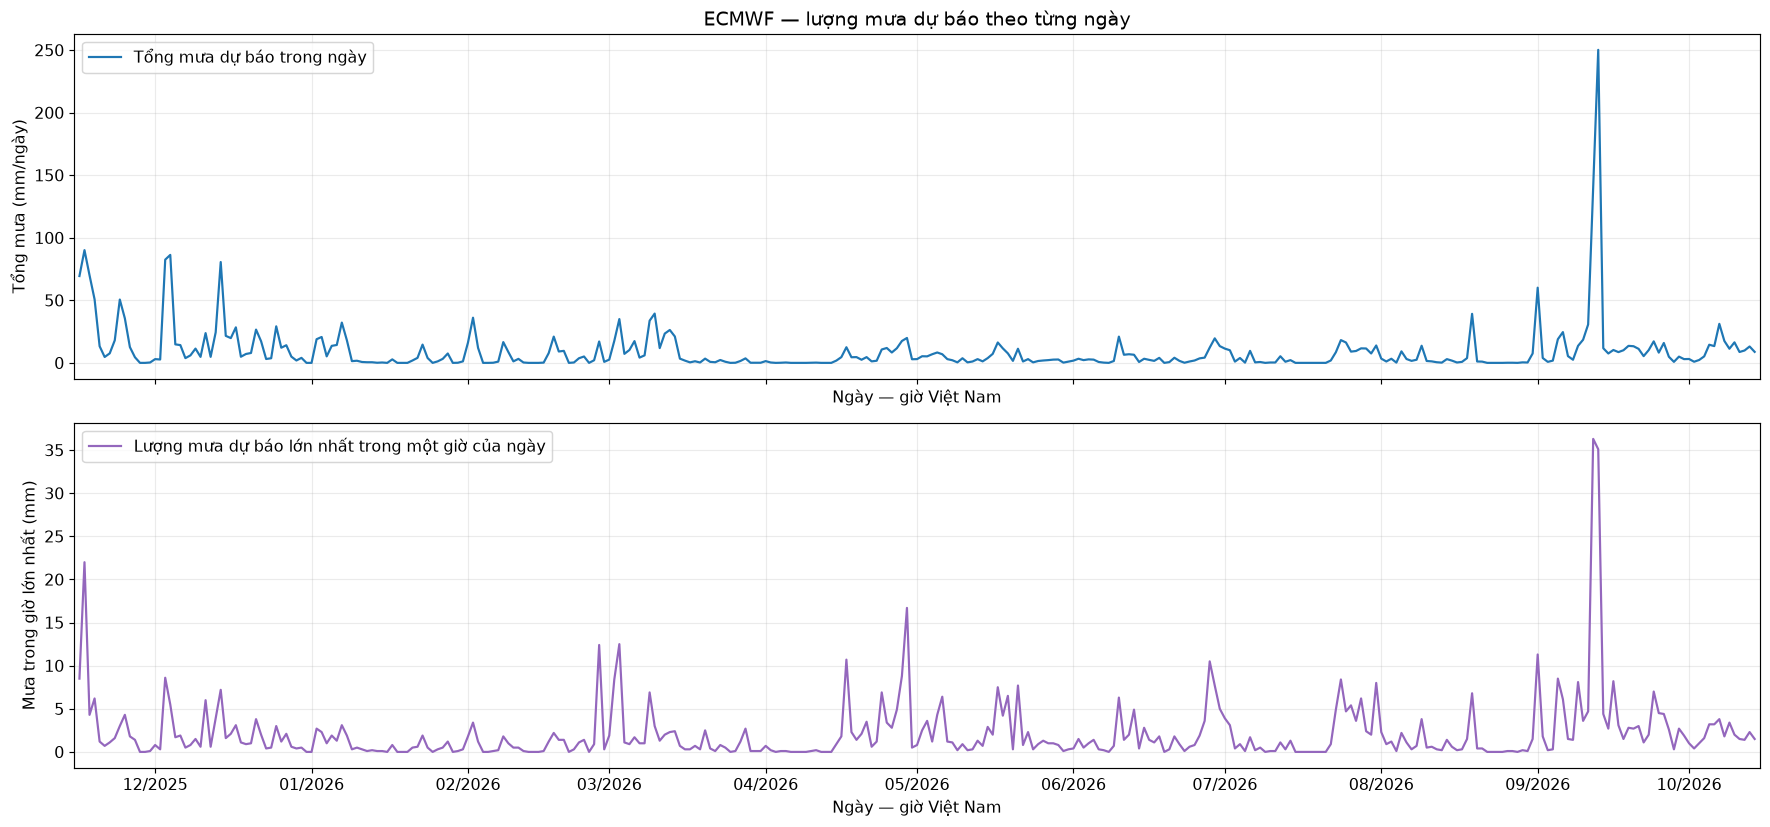

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(17, 8), sharex=True)
axes[0].plot(daily.index, daily.forecast_rain_mm, color='tab:blue',
             label='Tổng mưa dự báo trong ngày')
axes[0].set_ylabel('Tổng mưa (mm/ngày)')
axes[0].set_title('ECMWF — lượng mưa dự báo theo từng ngày')
axes[1].plot(daily.index, daily.forecast_max_hour_mm, color='tab:purple',
             label='Lượng mưa dự báo lớn nhất trong một giờ của ngày')
axes[1].set_ylabel('Mưa trong giờ lớn nhất (mm)')
for ax in axes:
    format_time_axis(ax)
    ax.legend(loc='upper left')
finish(fig, '01_du_bao_mua_theo_ngay.png')


## 2. So sánh tổng mưa dự báo và tổng mưa thực tế mỗi ngày

So sánh cùng một ngày lịch. Đường bị ngắt khi thiếu dữ liệu; không điền bằng 0.


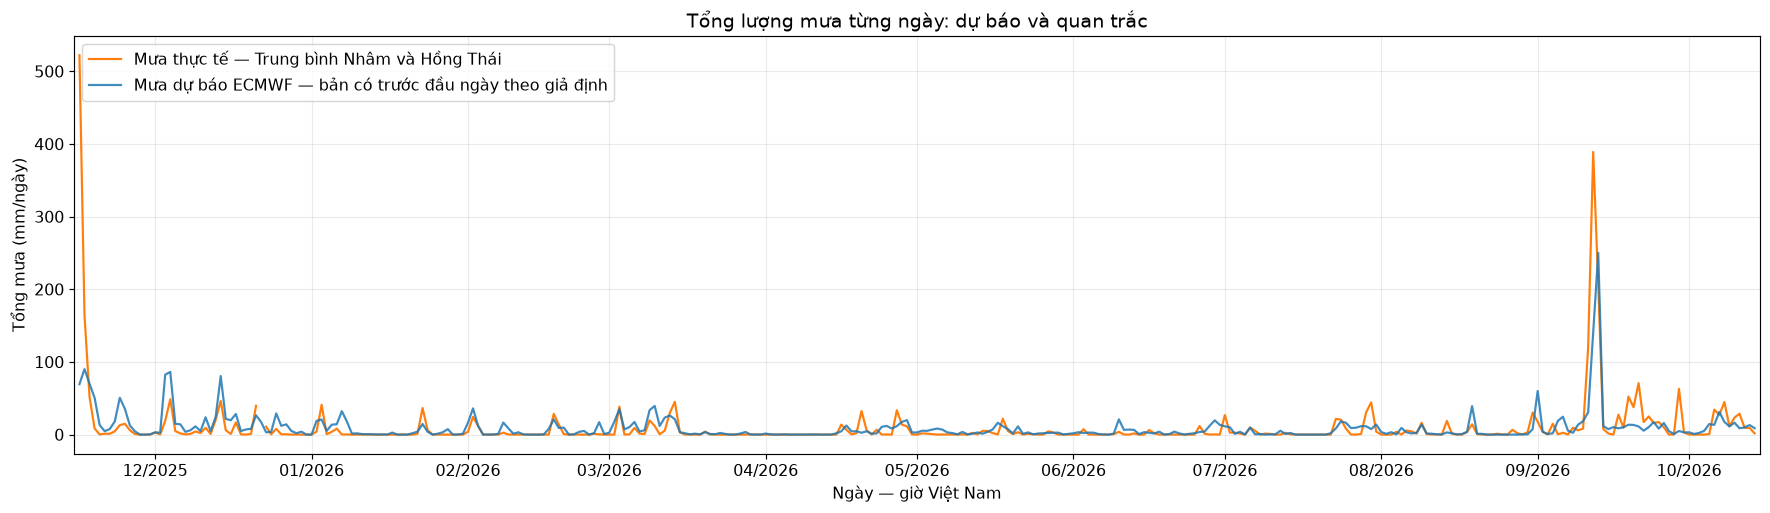

In [6]:
fig, ax = plt.subplots()
ax.plot(daily.index, daily.observed_rain_mm, color='tab:orange',
        label=f'Mưa thực tế — {rain_label}')
ax.plot(daily.index, daily.forecast_rain_mm, color='tab:blue', alpha=0.85,
        label='Mưa dự báo ECMWF — bản có trước đầu ngày theo giả định')
ax.set_title('Tổng lượng mưa từng ngày: dự báo và quan trắc')
ax.set_ylabel('Tổng mưa (mm/ngày)')
format_time_axis(ax)
ax.legend(loc='upper left')
finish(fig, '02_du_bao_va_mua_thuc_te.png')


## 3–4. Lượng mưa và mực nước Dã Viên

Dùng hai trục y với đơn vị riêng: mưa tổng ngày và mực nước trung bình ngày.
Đây là đối chiếu hình dạng theo thời gian, **chưa ước lượng độ trễ hoặc quan hệ nhân quả**.
Không dịch đường mưa để ép khớp với mực nước.


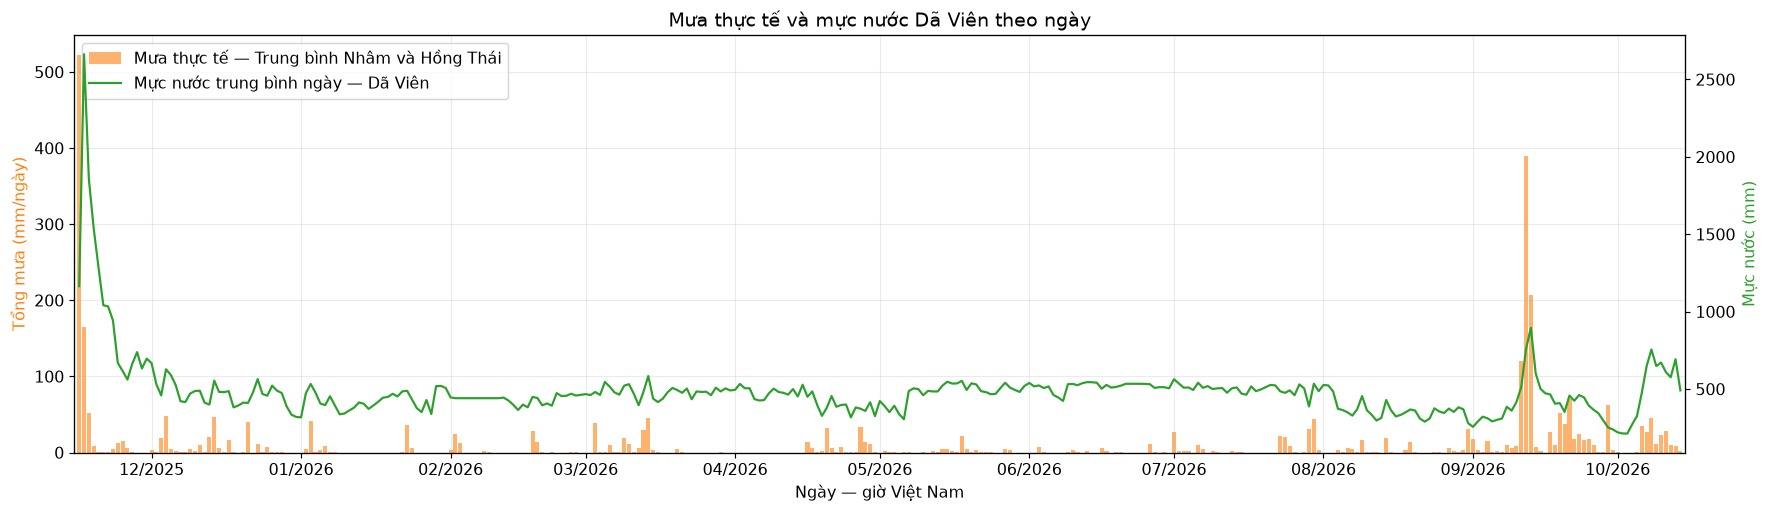

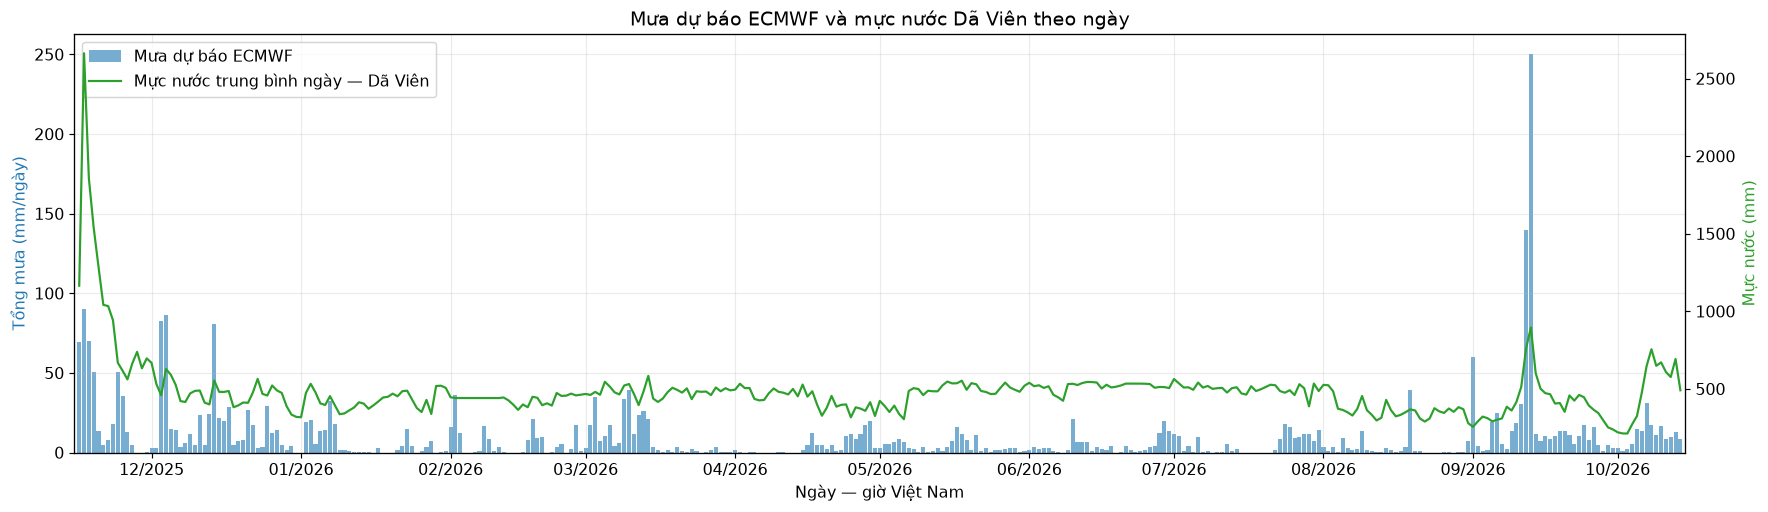

In [7]:
def plot_rain_and_water(column, title, label, color, filename):
    fig, ax = plt.subplots()
    ax.bar(daily.index, daily[column], width=0.85, color=color, alpha=0.6,
           label=label)
    ax.set_ylabel('Tổng mưa (mm/ngày)', color=color)
    water_ax = ax.twinx()
    water_ax.plot(daily.index, daily.water_level_mean_mm, color='tab:green',
                  linewidth=1.5, label='Mực nước trung bình ngày — Dã Viên')
    water_ax.set_ylabel('Mực nước (mm)', color='tab:green')
    ax.set_title(title)
    format_time_axis(ax)
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = water_ax.get_legend_handles_labels()
    ax.legend(handles1 + handles2, labels1 + labels2, loc='upper left')
    finish(fig, filename)

plot_rain_and_water('observed_rain_mm', 'Mưa thực tế và mực nước Dã Viên theo ngày',
                    f'Mưa thực tế — {rain_label}', 'tab:orange',
                    '03_mua_thuc_te_va_muc_nuoc.png')
plot_rain_and_water('forecast_rain_mm', 'Mưa dự báo ECMWF và mực nước Dã Viên theo ngày',
                    'Mưa dự báo ECMWF', 'tab:blue',
                    '04_mua_du_bao_va_muc_nuoc.png')


In [8]:
manifest = {
    'dataset_dir': str(DATASET_DIR), 'start_utc': str(start_utc), 'end_utc': str(end_utc),
    'rain_mode': RAIN_MODE, 'observed_station_ids': selected_rain_ids,
    'forecast_station_id': FORECAST_STATION_ID, 'assumed_release_lag_hours': ASSUMED_RELEASE_LAG_HOURS,
    'forecast_policy': 'one latest initialized run before local midnight minus assumed lag; max age 18h',
    'missing_policy': 'require 24 non-null hourly values; no zero fill or fallback',
    'archive_warning': 'hindcast and historical publication availability not verified',
    'split_checksums': {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                        for p in DATASET_DIR.glob('*.csv') if p.stem in {'train', 'val', 'test'}},
    'days': len(daily), 'complete_forecast_days': int(daily.forecast_rain_mm.notna().sum()),
}
(OUTPUT_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
print(f'Figure, bảng ngày và manifest: {OUTPUT_DIR}')


Figure, bảng ngày và manifest: /home/my_ubuntu/projects/hydrology/reports/weather_collection/daily_analysis


## 5. Correlation mưa và mực nước sau 1/3/6/12/24 giờ

**Định nghĩa chính xác:** Pearson giữa lượng mưa trong khoảng `(t−1h,t]` và mực
nước trung bình trong giờ kết thúc tại `t+h`, với h = 1, 3, 6, 12, 24 giờ.
Mưa thực tế dùng cùng lựa chọn `RAIN_MODE` bên trên.

Mưa dự báo cũng mô tả khoảng `(t−1h,t]`, nhưng được lấy từ bản mới nhất được giả
định đã có **trước đầu khoảng mưa `t−1h`**: khởi tạo + 6 giờ ≤ t−1h. Vì thế,
**h là độ trễ từ giờ mưa đến giờ nước, không phải lead time từ lúc phát hành dự báo**.
Cách chọn bản này khác biểu đồ ngày ở trên (cố định một bản trước đầu ngày).
Không dùng bản đã khởi tạo sau giờ mưa hoặc cộng các bản dự báo trùng nhau.
Nếu bản mới nhất thiếu thì giữ thiếu, chưa fallback về bản cũ hơn.

Tại mỗi horizon, hai loại mưa được so trên **cùng các cặp thời gian hợp lệ**.
Với train/val/test, cả `t` và `t+h` phải nằm trong cùng split, tránh lấy nhãn của
split sau. Toàn khoảng dữ liệu có thể bao gồm các giờ purge.

Đây là tương quan với **mực nước tuyệt đối**, chưa phải tương quan với mức tăng
nước. Tính mùa vụ, tự tương quan và điều tiết hồ có thể ảnh hưởng kết quả; không
kết luận quan hệ nhân quả hoặc độ trễ tối ưu chỉ từ năm mốc này. Kết quả toàn
khoảng dùng để mô tả; chỉ dùng train để đề xuất feature.


In [9]:
import bisect
HORIZONS = [1, 3, 6, 12, 24]
hour_index = pd.date_range(start_utc, end_utc, freq='h')
analysis_hourly = pd.DataFrame(index=hour_index)
rain_hourly = pd.concat([observed_hourly[sid].reindex(hour_index)
                        for sid in selected_rain_ids], axis=1)
analysis_hourly['observed_rain_mm'] = rain_hourly.mean(axis=1, skipna=False)
analysis_hourly['water_level_mm'] = observed_hourly[WATER_ID].reindex(hour_index)
run_times = list(run_meta.initialized_at)
forecast_values, selected_cycles = [], []
for stamp in hour_index:
    cutoff = stamp - pd.Timedelta(hours=1 + ASSUMED_RELEASE_LAG_HOURS)
    position = bisect.bisect_right(run_times, cutoff) - 1
    value, cycle = np.nan, pd.NaT
    if position >= 0:
        chosen = run_meta.iloc[position]
        age = (stamp - chosen.initialized_at).total_seconds() / 3600
        # Không kéo dài vô hạn một bản cũ khi một chu kỳ bị thiếu.
        if age < ASSUMED_RELEASE_LAG_HOURS + 7:
            cycle = chosen.initialized_at
            value = forecast_by_run[chosen.run_id].get(stamp, np.nan)
    forecast_values.append(value)
    selected_cycles.append(cycle)
analysis_hourly['forecast_rain_mm'] = forecast_values
analysis_hourly['run_initialized_at'] = selected_cycles

scope_indexes = {'all': hour_index,
                 **{name: pd.DatetimeIndex(stamps) for name, stamps
                    in zip(['train', 'val', 'test'], split_times)}}
results = []
for scope, scope_index in scope_indexes.items():
    for horizon in HORIZONS:
        targets = hour_index + pd.Timedelta(hours=horizon)
        eligible = hour_index.isin(scope_index) & targets.isin(scope_index)
        pair = analysis_hourly[['observed_rain_mm', 'forecast_rain_mm']].copy()
        pair['future_water_level_mm'] = analysis_hourly.water_level_mm.reindex(targets).to_numpy()
        pair = pair.loc[eligible].dropna()
        for source in ['observed_rain_mm', 'forecast_rain_mm']:
            r = pair[source].corr(pair.future_water_level_mm) if len(pair) > 1 else np.nan
            results.append({'scope': scope, 'horizon_hours': horizon, 'source': source,
                            'n_pairs': len(pair), 'pearson_r': r,
                            'eligible_hours': int(eligible.sum()),
                            'coverage_pct': 100 * len(pair) / eligible.sum() if eligible.sum() else np.nan})
correlations = pd.DataFrame(results)
correlations.to_csv(OUTPUT_DIR / 'hourly_rain_water_correlations.csv', index=False)
analysis_hourly.to_csv(OUTPUT_DIR / 'hourly_rain_water_alignment.csv', index_label='rain_hour_end_utc')
for scope in scope_indexes:
    part = correlations[correlations.scope == scope]
    table = part.pivot(index='horizon_hours', columns='source', values='pearson_r')
    table = table.rename(columns={'observed_rain_mm': 'r mưa thực tế → nước',
                                  'forecast_rain_mm': 'r mưa dự báo → nước'})
    table['Số cặp chung'] = part.groupby('horizon_hours').n_pairs.first()
    table['Độ phủ (%)'] = part.groupby('horizon_hours').coverage_pct.first()
    print(f'Phạm vi: {scope}')
    display(table.round(4))


Phạm vi: all
Phạm vi: train
Phạm vi: val
Phạm vi: test


source,r mưa dự báo → nước,r mưa thực tế → nước,Số cặp chung,Độ phủ (%)
horizon_hours,,,,
1,0.2811,0.2656,8014,99.8256
3,0.2942,0.2802,8012,99.8256
6,0.3078,0.3085,8009,99.8255
12,0.3400,0.3914,8003,99.8254
24,0.2857,0.4054,7991,99.8251


source,r mưa dự báo → nước,r mưa thực tế → nước,Số cặp chung,Độ phủ (%)
horizon_hours,,,,
1,0.3323,0.2829,6175,99.7738
3,0.3519,0.3063,6173,99.7737
6,0.3785,0.3458,6170,99.7736
12,0.3960,0.4530,6164,99.7734
24,0.3358,0.5023,6152,99.7729


source,r mưa dự báo → nước,r mưa thực tế → nước,Số cặp chung,Độ phủ (%)
horizon_hours,,,,
1,0.4315,0.5563,1079,100.0
3,0.4372,0.5579,1077,100.0
6,0.4297,0.5677,1074,100.0
12,0.5057,0.5988,1068,100.0
24,0.4496,0.4852,1056,100.0


source,r mưa dự báo → nước,r mưa thực tế → nước,Số cặp chung,Độ phủ (%)
horizon_hours,,,,
1,0.1557,0.1083,710,100.0
3,0.1580,0.0772,708,100.0
6,0.1307,0.0725,705,100.0
12,0.2788,0.1331,699,100.0
24,0.1867,0.0800,687,100.0


Đã lưu bảng correlation và figure vào /home/my_ubuntu/projects/hydrology/reports/weather_collection/daily_analysis


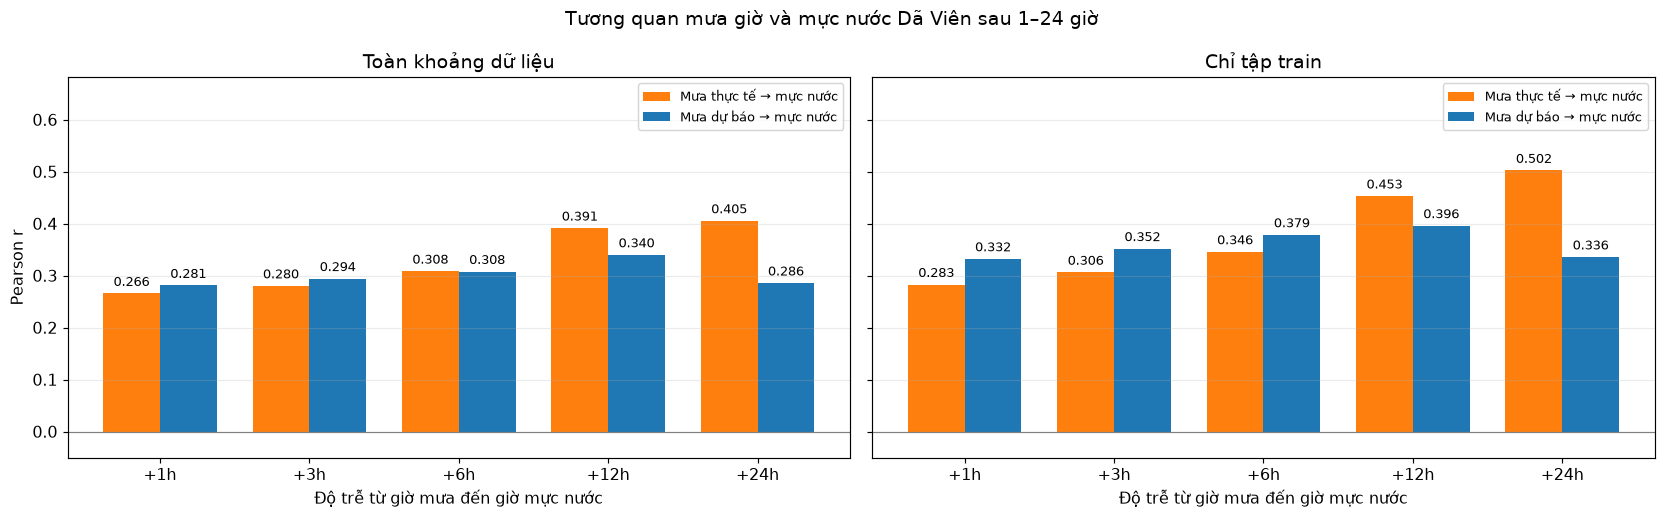

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, scope, title in zip(axes, ['all', 'train'], ['Toàn khoảng dữ liệu', 'Chỉ tập train']):
    part = correlations[correlations.scope == scope]
    x = np.arange(len(HORIZONS))
    for offset, source, label, color in [
        (-0.19, 'observed_rain_mm', 'Mưa thực tế → mực nước', 'tab:orange'),
        (0.19, 'forecast_rain_mm', 'Mưa dự báo → mực nước', 'tab:blue')]:
        values = part[part.source == source].set_index('horizon_hours').reindex(HORIZONS).pearson_r
        bars = ax.bar(x + offset, values, width=0.38, color=color, label=label)
        ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
    ax.set_xticks(x, [f'+{h}h' for h in HORIZONS])
    ax.set_xlabel('Độ trễ từ giờ mưa đến giờ mực nước')
    ax.set_title(title)
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.grid(axis='y', alpha=0.25)
    ax.legend(loc='upper right', fontsize=9)
axes[0].set_ylabel('Pearson r')
low = correlations[correlations.scope.isin(['all', 'train'])].pearson_r.min()
high = correlations[correlations.scope.isin(['all', 'train'])].pearson_r.max()
axes[0].set_ylim(min(-0.05, low - 0.08), min(1.05, high + 0.18))
fig.suptitle('Tương quan mưa giờ và mực nước Dã Viên sau 1–24 giờ')
finish(fig, '05_correlation_mua_va_muc_nuoc.png')

lines = ['# Correlation mưa giờ và mực nước Dã Viên', '',
         'Pearson r; t là giờ kết thúc khoảng mưa, h là độ trễ mưa–nước. '
         'Mưa dự báo chọn bản khởi tạo + 6 giờ không muộn hơn t−1h; '
         'độ trễ công bố là giả định. Mỗi horizon dùng cùng cặp hợp lệ cho hai nguồn.', '',
         f'Mưa quan trắc: {rain_label}. Khoảng: {start_utc} → {end_utc}.', '']
for scope in scope_indexes:
    lines += [f'## {scope}', '', '| Sau giờ mưa | r thực tế | r dự báo | Số cặp chung |',
              '|---|---:|---:|---:|']
    part = correlations[correlations.scope == scope]
    for h in HORIZONS:
        rows = part[part.horizon_hours == h].set_index('source')
        lines.append(f"| +{h}h | {rows.loc['observed_rain_mm', 'pearson_r']:.4f} | "
                     f"{rows.loc['forecast_rain_mm', 'pearson_r']:.4f} | "
                     f"{int(rows.iloc[0].n_pairs)} |")
    lines.append('')
lines += ['Không diễn giải r là độ chính xác dự báo nước; chưa đo quan hệ với mức tăng nước. '
          'Không chọn feature từ toàn khoảng/val/test. Các mẫu theo giờ có tự tương quan; '
          'chưa có kiểm định ý nghĩa thống kê theo các đợt độc lập.']
(OUTPUT_DIR / 'correlation_report.md').write_text('\n'.join(lines) + '\n')
print(f'Đã lưu bảng correlation và figure vào {OUTPUT_DIR}')


## 6. Correlation giữa mưa dự báo và mưa thực tế

So cùng **giờ mưa xảy ra** hoặc cùng **ngày lịch**; không dịch trễ mưa–nước.

- Theo giờ: giữ cách chọn bản trước đầu khoảng mưa ở phần 5.
- Theo ngày: giữ một bản trước đầu ngày ở phần 1–2, rồi cộng đủ 24 giờ.
- Pearson r đo quan hệ tuyến tính; Spearman đo quan hệ thứ hạng. r cao không có
  nghĩa dự báo đúng biên độ. Bổ sung bias/MAE và đường y=x để nhận biết dự báo
  thiếu hoặc thừa. Đây là thống kê mô tả, không phải kiểm định độc lập theo đợt mưa.
- Mưa quan trắc vẫn là lựa chọn `RAIN_MODE`; không điền dữ liệu thiếu bằng 0.


,resolution,scope,n_pairs,pearson_r,spearman_r,observed_mean_mm,forecast_mean_mm,bias_mm,mae_mm
0,hourly,all,8015,0.3885,0.4611,0.4124,0.3673,-0.0452,0.5229
1,hourly,train,6176,0.2852,0.4738,0.3010,0.3347,0.0337,0.4334
2,hourly,val,1080,0.5886,0.4592,0.8341,0.5150,-0.3191,0.7872
3,hourly,test,711,0.0829,0.3384,0.7602,0.4121,-0.3481,0.8963
4,daily,all,332,0.6334,0.6917,9.7723,9.3883,-0.3840,9.0840


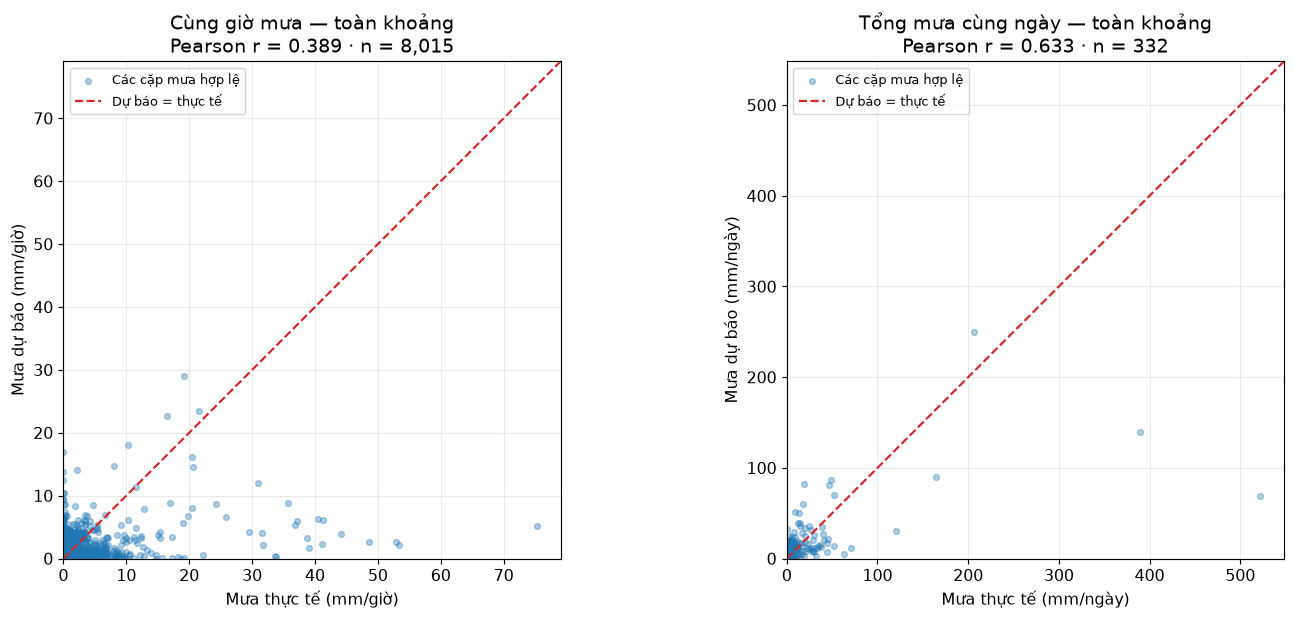

In [11]:
agreement_rows = []
agreement_pairs = {}
for scope, idx in scope_indexes.items():
    pair = analysis_hourly.loc[analysis_hourly.index.isin(idx),
                               ['observed_rain_mm', 'forecast_rain_mm']].dropna()
    agreement_pairs[f'hourly_{scope}'] = pair
    agreement_rows.append({'resolution': 'hourly', 'scope': scope, 'n_pairs': len(pair),
        'pearson_r': pair.observed_rain_mm.corr(pair.forecast_rain_mm),
        'spearman_r': pair.observed_rain_mm.rank().corr(pair.forecast_rain_mm.rank()),
        'observed_mean_mm': pair.observed_rain_mm.mean(),
        'forecast_mean_mm': pair.forecast_rain_mm.mean(),
        'bias_mm': (pair.forecast_rain_mm - pair.observed_rain_mm).mean(),
        'mae_mm': (pair.forecast_rain_mm - pair.observed_rain_mm).abs().mean()})
pair = daily[['observed_rain_mm', 'forecast_rain_mm']].dropna()
agreement_pairs['daily_all'] = pair
agreement_rows.append({'resolution': 'daily', 'scope': 'all', 'n_pairs': len(pair),
    'pearson_r': pair.observed_rain_mm.corr(pair.forecast_rain_mm),
    'spearman_r': pair.observed_rain_mm.rank().corr(pair.forecast_rain_mm.rank()),
    'observed_mean_mm': pair.observed_rain_mm.mean(),
    'forecast_mean_mm': pair.forecast_rain_mm.mean(),
    'bias_mm': (pair.forecast_rain_mm - pair.observed_rain_mm).mean(),
    'mae_mm': (pair.forecast_rain_mm - pair.observed_rain_mm).abs().mean()})
rain_agreement = pd.DataFrame(agreement_rows)
display(rain_agreement.round(4))
rain_agreement.to_csv(OUTPUT_DIR / 'forecast_observed_rain_correlations.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, key, title, unit in zip(axes, ['hourly_all', 'daily_all'],
        ['Cùng giờ mưa — toàn khoảng', 'Tổng mưa cùng ngày — toàn khoảng'],
        ['mm/giờ', 'mm/ngày']):
    pair = agreement_pairs[key]
    ax.scatter(pair.observed_rain_mm, pair.forecast_rain_mm,
               alpha=0.35, s=16, color='tab:blue', label='Các cặp mưa hợp lệ')
    limit = max(pair.max().max(), 1) * 1.05
    ax.plot([0, limit], [0, limit], color='tab:red', linestyle='--', label='Dự báo = thực tế')
    ax.set_xlim(0, limit); ax.set_ylim(0, limit); ax.set_aspect('equal', adjustable='box')
    r = pair.observed_rain_mm.corr(pair.forecast_rain_mm)
    ax.set_title(f'{title}\nPearson r = {r:.3f} · n = {len(pair):,}')
    ax.set_xlabel(f'Mưa thực tế ({unit})')
    ax.set_ylabel(f'Mưa dự báo ({unit})')
    ax.grid(alpha=0.25); ax.legend(loc='upper left', fontsize=9)
finish(fig, '06_correlation_du_bao_va_mua_thuc_te.png')

report_lines = ['# Correlation giữa mưa dự báo và thực tế', '',
    f'Mưa thực tế: {rain_label}. Căn cùng giờ/ngày mưa; không dịch theo độ trễ mực nước.', '',
    'Theo giờ: bản khởi tạo + giả định trễ 6 giờ ≤ đầu khoảng mưa. '
    'Theo ngày: một bản trước đầu ngày theo cùng giả định. Hai cách chọn có lead time khác nhau.', '',
    '| Độ phân giải | Phạm vi | Số cặp | Pearson r | Spearman r | Bias (mm) | MAE (mm) |',
    '|---|---|---:|---:|---:|---:|---:|']
for row in rain_agreement.itertuples():
    report_lines.append(f'| {row.resolution} | {row.scope} | {row.n_pairs} | '
        f'{row.pearson_r:.4f} | {row.spearman_r:.4f} | {row.bias_mm:.3f} | {row.mae_mm:.3f} |')
report_lines += ['', 'Bias = dự báo − thực tế. Đơn vị theo giờ là mm trong một giờ; '
    'theo ngày là mm trong một ngày. r không đo trực tiếp độ đúng biên độ. '
    'Không diễn giải chênh lệch r giờ/ngày chỉ do phép cộng vì cách chọn bản cũng khác nhau. '
    'Archive gồm hindcast; chưa xác minh thời điểm phát hành lịch sử.']
(OUTPUT_DIR / 'forecast_observed_rain_report.md').write_text('\n'.join(report_lines) + '\n')


## 7. So sánh tổng và trung bình mưa giờ với trung bình mực nước

Mưa quan trắc được tổng hợp theo hai cách từ cùng số đo gốc trong `(t−1h,t]`:
**sum** (cộng) và **mean** (trung bình số học). Sau đó vẫn trung bình hai trạm
hoặc chỉ Nhâm theo `RAIN_MODE`. Mean số đo nguồn không tự động là tổng lượng mưa
hoặc cường suất vật lý nếu chưa biết khoảng tích lũy của sensor.

ECMWF chỉ trả một tổng giáng thủy trong mỗi giờ. Không có chuỗi số đo dưới giờ
để tính mean như sensor. Trung bình cường suất trên một giờ = tổng mm / 1 giờ,
giữ nguyên trị số; vì vậy correlation không đổi. Không tự chia dự báo cho 6.

Nếu số đo mỗi giờ luôn là n cố định, sum = n × mean; Pearson không thay đổi
khi nhân một biến với hằng số dương. Chỉ số lượng/độ phân bố mẫu biến đổi mới
có thể làm hai correlation khác nhau. Bảng và biểu đồ dùng cùng mẫu cho mọi cách.


Phân bố số số đo mưa mỗi giờ (kể cả giờ đầu/cuối dataset):
Phạm vi: all
Phạm vi: train
Phạm vi: val
Phạm vi: test


,750007,750062
Số số đo hợp lệ trong giờ,,
5.0,2,11
6.0,8026,8014
NaN,1,1
0.0,0,1
2.0,0,1
4.0,0,1


source,forecast_hour_mean_rate,forecast_rain_mm,observed_rain_hour_mean,observed_rain_mm
horizon_hours,,,,
1,0.281079,0.281079,0.265634,0.265633
3,0.294243,0.294243,0.280203,0.280202
6,0.307835,0.307835,0.308479,0.308478
12,0.339959,0.339959,0.391357,0.391357
24,0.285726,0.285726,0.405422,0.405423


source,forecast_hour_mean_rate,forecast_rain_mm,observed_rain_hour_mean,observed_rain_mm
horizon_hours,,,,
1,0.332269,0.332269,0.282888,0.282888
3,0.351859,0.351859,0.306296,0.306294
6,0.378516,0.378516,0.345792,0.345792
12,0.395953,0.395953,0.453036,0.453038
24,0.335782,0.335782,0.502320,0.502321


source,forecast_hour_mean_rate,forecast_rain_mm,observed_rain_hour_mean,observed_rain_mm
horizon_hours,,,,
1,0.431518,0.431518,0.556310,0.556310
3,0.437186,0.437186,0.557855,0.557855
6,0.429727,0.429727,0.567744,0.567744
12,0.505718,0.505718,0.598835,0.598835
24,0.449650,0.449650,0.485233,0.485233


source,forecast_hour_mean_rate,forecast_rain_mm,observed_rain_hour_mean,observed_rain_mm
horizon_hours,,,,
1,0.155705,0.155705,0.108294,0.108294
3,0.158042,0.158042,0.077244,0.077244
6,0.130698,0.130698,0.072545,0.072545
12,0.278797,0.278797,0.133076,0.133076
24,0.186661,0.186661,0.079990,0.079990


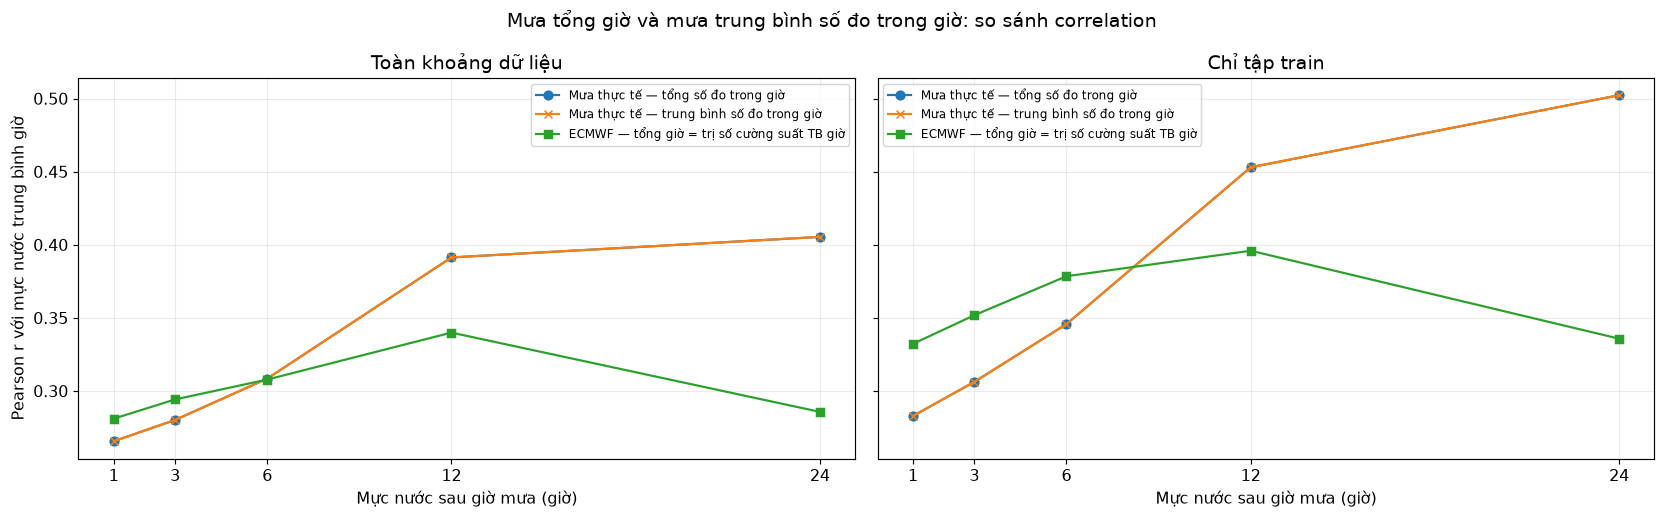

In [12]:
rain_hour_means, rain_hour_counts = {}, {}
for sid in selected_rain_ids:
    raw = observed.loc[observed.station_id == sid].set_index('observed_at').depth.astype(float)
    groups = raw.resample('1h', closed='right', label='right')
    rain_hour_means[sid] = groups.mean().reindex(hour_index)
    rain_hour_counts[sid] = groups.count().reindex(hour_index)
mean_comparison = analysis_hourly.copy()
mean_comparison['observed_rain_hour_mean'] = pd.DataFrame(rain_hour_means).mean(axis=1, skipna=False)
# Một giá trị ECMWF mỗi giờ: sum và mean trên cửa sổ một giờ trùng trị số.
mean_comparison['forecast_hour_mean_rate'] = mean_comparison.forecast_rain_mm / 1.0
count_summary = pd.concat({sid: counts.value_counts(dropna=False).sort_index()
                          for sid, counts in rain_hour_counts.items()}, axis=1).fillna(0).astype(int)
count_summary.index.name = 'Số số đo hợp lệ trong giờ'
print('Phân bố số số đo mưa mỗi giờ (kể cả giờ đầu/cuối dataset):')
display(count_summary)
mean_results = []
sources = ['observed_rain_mm', 'observed_rain_hour_mean',
           'forecast_rain_mm', 'forecast_hour_mean_rate']
for scope, scope_index in scope_indexes.items():
    for h in HORIZONS:
        target_times = hour_index + pd.Timedelta(hours=h)
        eligible = hour_index.isin(scope_index) & target_times.isin(scope_index)
        pair = mean_comparison[sources].copy()
        pair['future_water'] = analysis_hourly.water_level_mm.reindex(target_times).to_numpy()
        pair = pair.loc[eligible].dropna()
        for source in sources:
            mean_results.append(dict(scope=scope, horizon_hours=h, source=source,
                                     n_pairs=len(pair), pearson_r=pair[source].corr(pair.future_water)))
mean_correlations = pd.DataFrame(mean_results)
for scope in scope_indexes:
    print('Phạm vi:', scope)
    display(mean_correlations[mean_correlations.scope == scope].pivot(
        index='horizon_hours', columns='source', values='pearson_r').round(6))
mean_correlations.to_csv(OUTPUT_DIR / 'rain_sum_vs_mean_correlations.csv', index=False)
count_summary.to_csv(OUTPUT_DIR / 'rain_hour_sample_counts.csv')

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
labels = {'observed_rain_mm':'Mưa thực tế — tổng số đo trong giờ',
          'observed_rain_hour_mean':'Mưa thực tế — trung bình số đo trong giờ',
          'forecast_rain_mm':'ECMWF — tổng giờ = trị số cường suất TB giờ'}
for ax, scope, title in zip(axes, ['all', 'train'], ['Toàn khoảng dữ liệu', 'Chỉ tập train']):
    part = mean_correlations[mean_correlations.scope == scope]
    for source, marker in zip(labels, ['o', 'x', 's']):
        values = part[part.source == source].set_index('horizon_hours').reindex(HORIZONS).pearson_r
        ax.plot(HORIZONS, values, marker=marker, label=labels[source])
    ax.set_title(title); ax.set_xticks(HORIZONS)
    ax.set_xlabel('Mực nước sau giờ mưa (giờ)'); ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc='best')
axes[0].set_ylabel('Pearson r với mực nước trung bình giờ')
fig.suptitle('Mưa tổng giờ và mưa trung bình số đo trong giờ: so sánh correlation')
finish(fig, '07_correlation_mua_tong_va_trung_binh.png')

lines = ['# Tổng và trung bình mưa giờ với mực nước trung bình giờ', '',
         'Mưa thực tế mean được tính lại từ số đo gốc; ECMWF chỉ có một giá trị tổng mỗi giờ. '
         'Trị số cường suất trung bình trên một giờ bằng tổng mm / 1 giờ; Pearson không đổi.', '']
for scope in scope_indexes:
    lines += [f'## {scope}', '', '| Độ trễ | Mưa thực tế sum | Mưa thực tế mean | ECMWF (cả hai cách) | Số cặp |',
              '|---|---:|---:|---:|---:|']
    part = mean_correlations[mean_correlations.scope == scope]
    for h in HORIZONS:
        rows = part[part.horizon_hours == h].set_index('source')
        lines.append(f"| +{h}h | {rows.loc['observed_rain_mm','pearson_r']:.6f} | "
                     f"{rows.loc['observed_rain_hour_mean','pearson_r']:.6f} | "
                     f"{rows.loc['forecast_rain_mm','pearson_r']:.6f} | {int(rows.iloc[0].n_pairs)} |")
    lines.append('')
(OUTPUT_DIR / 'rain_sum_vs_mean_report.md').write_text('\n'.join(lines) + '\n')


## 8. Xem rõ đợt mưa lớn 11–14/09/2026

Chọn bốn ngày 11–14/09/2026: quan trắc cho thấy mưa lớn ngày 12–13/09 và mực
nước Dã Viên tăng. Đợt tháng 11/2025 lớn hơn nhưng nằm sát đầu snapshot, thiếu
bối cảnh trước đợt; chọn tháng 9 để có chuỗi giờ trọn vẹn hơn.

Ba ô cùng trục thời gian: mưa thực tế/dự báo mỗi giờ; mực nước trung bình giờ;
và thay đổi mực nước so với giờ trước (dương là tăng, âm là giảm). Mưa thực tế
trung bình Nhâm/Hồng Thái theo cấu hình notebook. Mưa dự báo là bản mới nhất
đã có trước đầu từng giờ mưa theo giả định trễ công bố 6 giờ, không phải một bản
cố định phát hành trước toàn bộ bốn ngày. Không dịch đường mưa để khớp nước.


Mực nước nhỏ nhất/lớn nhất trong khoảng: 327.88 / 1254.08 mm
Đỉnh nước trong khoảng: 2026-09-13 04:00:00+07:00
Giờ có mưa thực tế lớn nhất: 2026-09-12 16:00:00+07:00 41.2 mm
Các bản dự báo trong figure thay đổi theo thời điểm; không cộng chúng thành một bản dự báo 4 ngày.


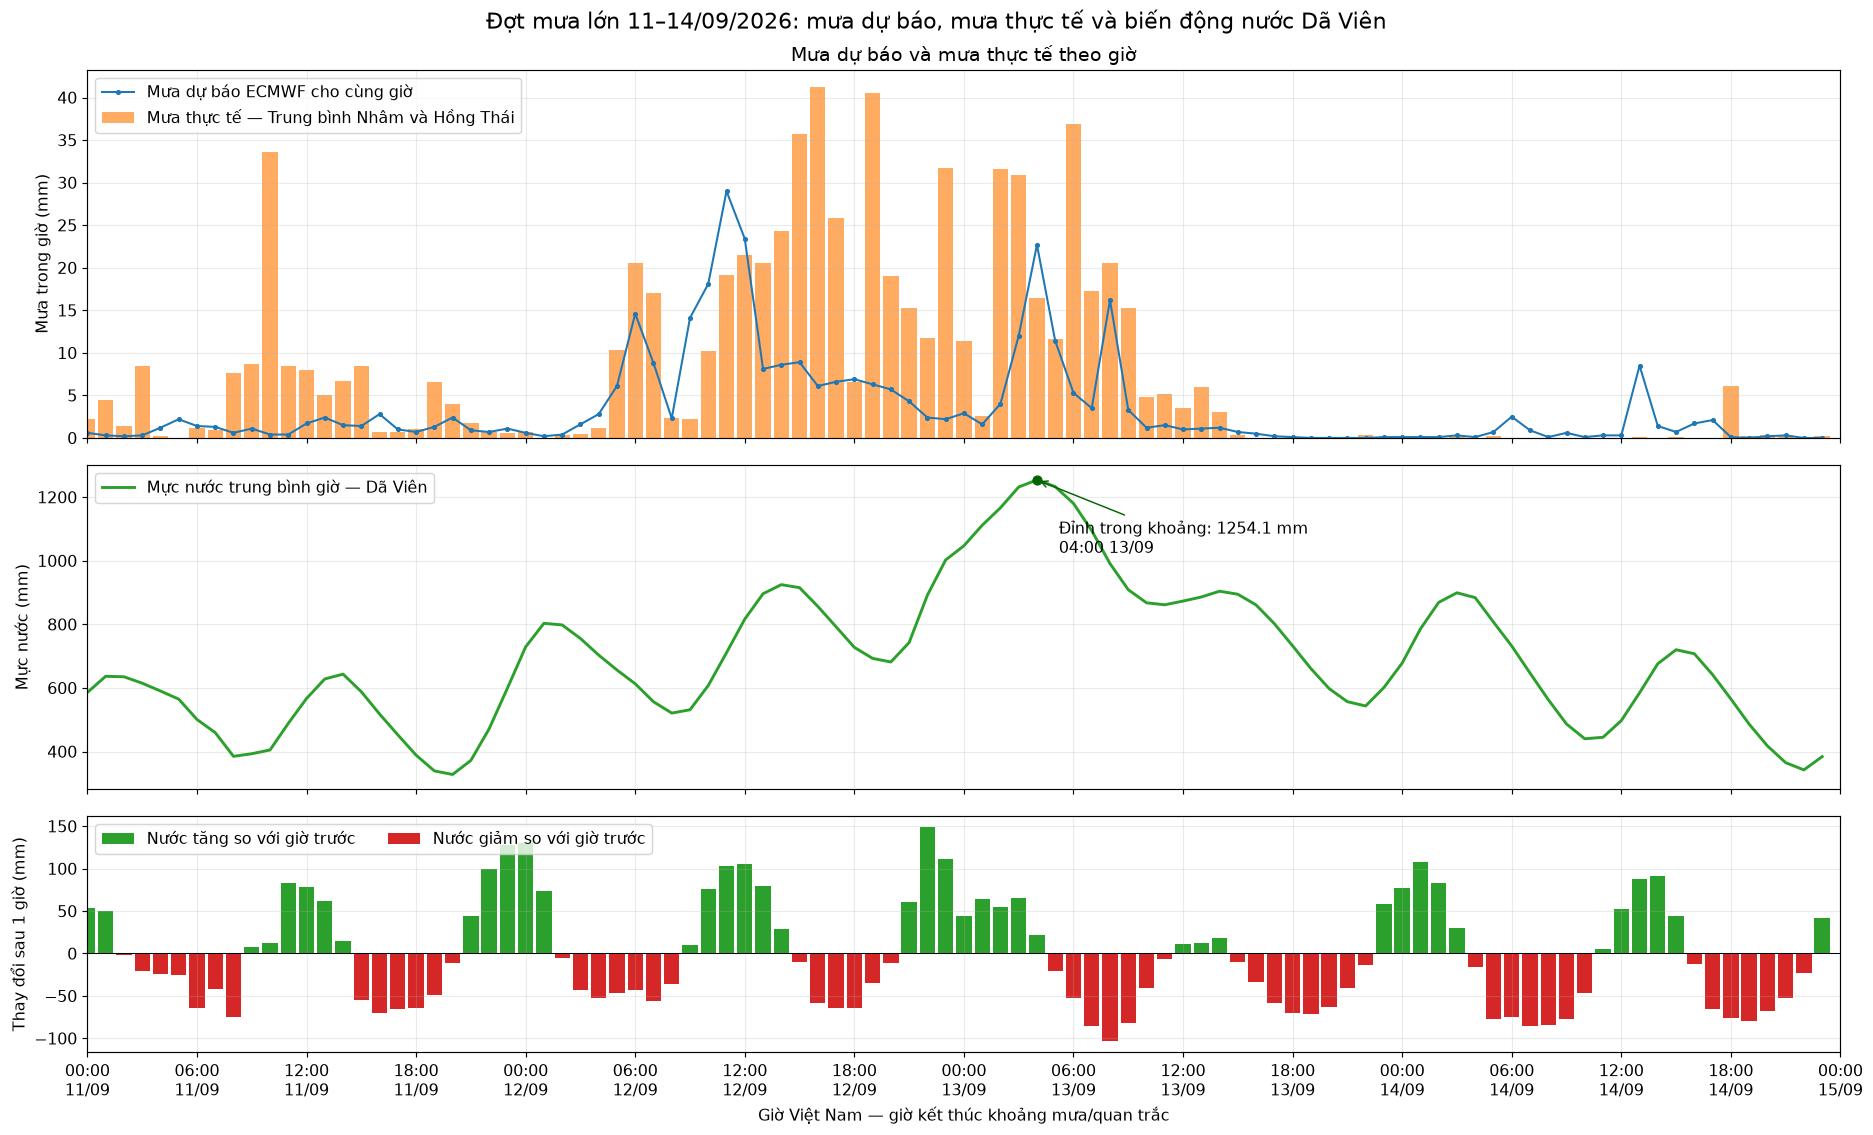

In [13]:
EVENT_START = pd.Timestamp('2026-09-11 00:00', tz=TZ)
EVENT_END = pd.Timestamp('2026-09-15 00:00', tz=TZ)  # không bao gồm
# Tính sai phân trên lưới giờ trước khi cắt khoảng để không mất giờ đầu sự kiện.
event_source = analysis_hourly.copy()
event_source['water_change_1h_mm'] = event_source.water_level_mm.diff()
event = event_source.loc[(event_source.index >= EVENT_START.tz_convert('UTC')) &
                          (event_source.index < EVENT_END.tz_convert('UTC'))].copy()
event.index = event.index.tz_convert(TZ)
assert len(event) == 96, 'Khoảng sự kiện chưa đủ 96 giờ'

fig, axes = plt.subplots(3, 1, figsize=(18, 11), sharex=True,
                         gridspec_kw={'height_ratios': [1.25, 1.1, 0.8]})
axes[0].bar(event.index, event.observed_rain_mm, width=0.035,
            color='tab:orange', alpha=0.65, label=f'Mưa thực tế — {rain_label}')
axes[0].plot(event.index, event.forecast_rain_mm, color='tab:blue', marker='o',
             markersize=2.5, linewidth=1.4, label='Mưa dự báo ECMWF cho cùng giờ')
axes[0].set_ylabel('Mưa trong giờ (mm)')
axes[0].set_title('Mưa dự báo và mưa thực tế theo giờ')
axes[0].legend(loc='upper left')
axes[1].plot(event.index, event.water_level_mm, color='tab:green', linewidth=2,
             label='Mực nước trung bình giờ — Dã Viên')
axes[1].set_ylabel('Mực nước (mm)')
axes[1].legend(loc='upper left')
peak_time = event.water_level_mm.idxmax()
peak_value = event.water_level_mm.max()
axes[1].scatter([peak_time], [peak_value], color='darkgreen', zorder=5)
axes[1].annotate(f'Đỉnh trong khoảng: {peak_value:.1f} mm\n{peak_time:%H:%M %d/%m}',
                 xy=(peak_time, peak_value), xytext=(15, -50), textcoords='offset points',
                 arrowprops={'arrowstyle':'->', 'color':'darkgreen'})
axes[2].bar(event.index, event.water_change_1h_mm.clip(lower=0), width=0.035,
            color='tab:green', label='Nước tăng so với giờ trước')
axes[2].bar(event.index, event.water_change_1h_mm.clip(upper=0), width=0.035,
            color='tab:red', label='Nước giảm so với giờ trước')
axes[2].axhline(0, color='black', linewidth=0.7)
axes[2].set_ylabel('Thay đổi sau 1 giờ (mm)')
axes[2].legend(loc='upper left', ncol=2)
for ax in axes:
    ax.grid(alpha=0.25)
    ax.set_xlim(EVENT_START, EVENT_END)
axes[2].xaxis.set_major_locator(mdates.HourLocator(byhour=[0,6,12,18], tz=event.index.tz))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M\n%d/%m', tz=event.index.tz))
axes[2].set_xlabel('Giờ Việt Nam — giờ kết thúc khoảng mưa/quan trắc')
fig.suptitle('Đợt mưa lớn 11–14/09/2026: mưa dự báo, mưa thực tế và biến động nước Dã Viên',
             fontsize=15)
finish(fig, '08_dot_mua_lon_11_14_09_2026.png')
event.to_csv(OUTPUT_DIR / 'event_11_14_09_2026_hourly.csv', index_label='hour_end_local')
print('Mực nước nhỏ nhất/lớn nhất trong khoảng:',
      round(event.water_level_mm.min(), 2), '/', round(event.water_level_mm.max(), 2), 'mm')
print('Đỉnh nước trong khoảng:', peak_time)
print('Giờ có mưa thực tế lớn nhất:', event.observed_rain_mm.idxmax(),
      round(event.observed_rain_mm.max(), 2), 'mm')
print('Các bản dự báo trong figure thay đổi theo thời điểm; không cộng chúng thành một bản dự báo 4 ngày.')


## 9. Nhiều đợt mưa lớn: thời gian đến khi nước tăng

Đây là phân tích mô tả theo sự kiện, **không phải đo thời gian truyền nước nhân quả**.
Mưa dùng trung bình hai trạm hoặc Nhâm theo cấu hình notebook.

Quy tắc được đặt trước khi tính:
- Giờ mưa: ít nhất 1 mm. Hai giờ mưa cách nhau hơn 6 giờ được tách thành đợt mới
  (có ít nhất 6 giờ ở giữa dưới ngưỡng). Đợt lớn có tổng từ 50 mm; đây là ngưỡng
  phục vụ phân tích, không phải phân loại khí tượng chính thức.
- Bắt đầu đợt là đầu khoảng của giờ mưa đầu tiên, không phải lúc phát hành dự báo.
- Nền nước: trung vị 6 giá trị giờ ngay trước và tại đầu đợt.
- Nước tăng rõ: ít nhất hai giờ liên tiếp cao hơn nền từ 50 mm; tìm trong 48 giờ
  sau bắt đầu mưa. Có bảng kiểm tra nhạy với ngưỡng 25/50/100 mm.
- Đánh dấu nước đã tăng trước mưa nếu mức nước tại đầu đợt cao hơn 3 giờ trước
  ít nhất 50 mm. Báo thống kê riêng nhóm chưa có xu hướng tăng này.
- Chỉ chấm sự kiện khi có đủ nền và 49 giờ nước sau đầu đợt. Không tìm thấy
  đáp ứng trong 48 giờ được giữ là thiếu, không coi độ trễ là 0 hoặc 48.
- Đo thêm khoảng cách từ đỉnh mưa giờ tới đỉnh nước trong 48 giờ tiếp theo.
  Chỉ số này luôn không âm do cửa sổ tìm kiếm, không dùng làm bằng chứng nhân quả.

Các đợt/mức nước có thể chịu ảnh hưởng của mưa vùng khác, thủy triều và điều tiết;
ngay cả sau khi loại nước đang tăng, một lần vượt ngưỡng cũng chưa chứng minh do mưa.

Cửa sổ của các đợt gần nhau có thể chồng lấn, nhất là tháng 9. Thống kê đỉnh
có thể bao gồm ảnh hưởng của đợt sau, nên chỉ xem là đối chiếu diễn biến; không
dùng nó để chốt thời gian phản ứng riêng của từng đợt.


Tổng đợt đạt ngưỡng: 9; đủ cửa sổ nước: 9


,group,metric,eligible_events,events_with_response,missing_response,min_hours,max_hours,mean_hours,median_hours
0,all_complete,lag_25mm_hours,9,9,0,1.0,11.0,4.00,2.0
1,all_complete,lag_50mm_hours,9,9,0,1.0,17.0,5.33,2.0
2,all_complete,lag_100mm_hours,9,9,0,1.0,36.0,8.22,3.0
3,all_complete,rain_peak_to_water_peak_hours,9,9,0,2.0,42.0,17.33,12.0
4,not_already_rising,lag_25mm_hours,5,5,0,2.0,11.0,6.40,7.0
5,not_already_rising,lag_50mm_hours,5,5,0,2.0,17.0,8.80,9.0
6,not_already_rising,lag_100mm_hours,5,5,0,3.0,36.0,14.00,10.0
7,not_already_rising,rain_peak_to_water_peak_hours,5,5,0,2.0,30.0,17.80,20.0


,event_id,onset_local,end_local,total_rain_mm,already_rising,complete_water_window,lag_50mm_hours,rain_peak_to_water_peak_hours
0,1,2025-11-16 06:00:00+07:00,2025-11-19 03:00:00+07:00,744.6,False,True,2.0,25.0
1,2,2025-12-03 11:00:00+07:00,2025-12-04 22:00:00+07:00,65.6,True,True,1.0,12.0
2,3,2025-12-13 13:00:00+07:00,2025-12-14 12:00:00+07:00,57.9,False,True,4.0,20.0
3,4,2025-12-21 02:00:00+07:00,2025-12-22 17:00:00+07:00,89.1,False,True,12.0,30.0
4,5,2026-03-12 20:00:00+07:00,2026-03-14 16:00:00+07:00,77.2,True,True,1.0,4.0
5,6,2026-09-10 23:00:00+07:00,2026-09-11 21:00:00+07:00,120.1,True,True,1.0,42.0
6,7,2026-09-12 03:00:00+07:00,2026-09-13 14:00:00+07:00,593.9,False,True,9.0,12.0
7,8,2026-09-20 13:00:00+07:00,2026-09-21 11:00:00+07:00,106.8,False,True,17.0,2.0
8,9,2026-09-29 13:00:00+07:00,2026-09-29 20:00:00+07:00,62.4,True,True,1.0,9.0


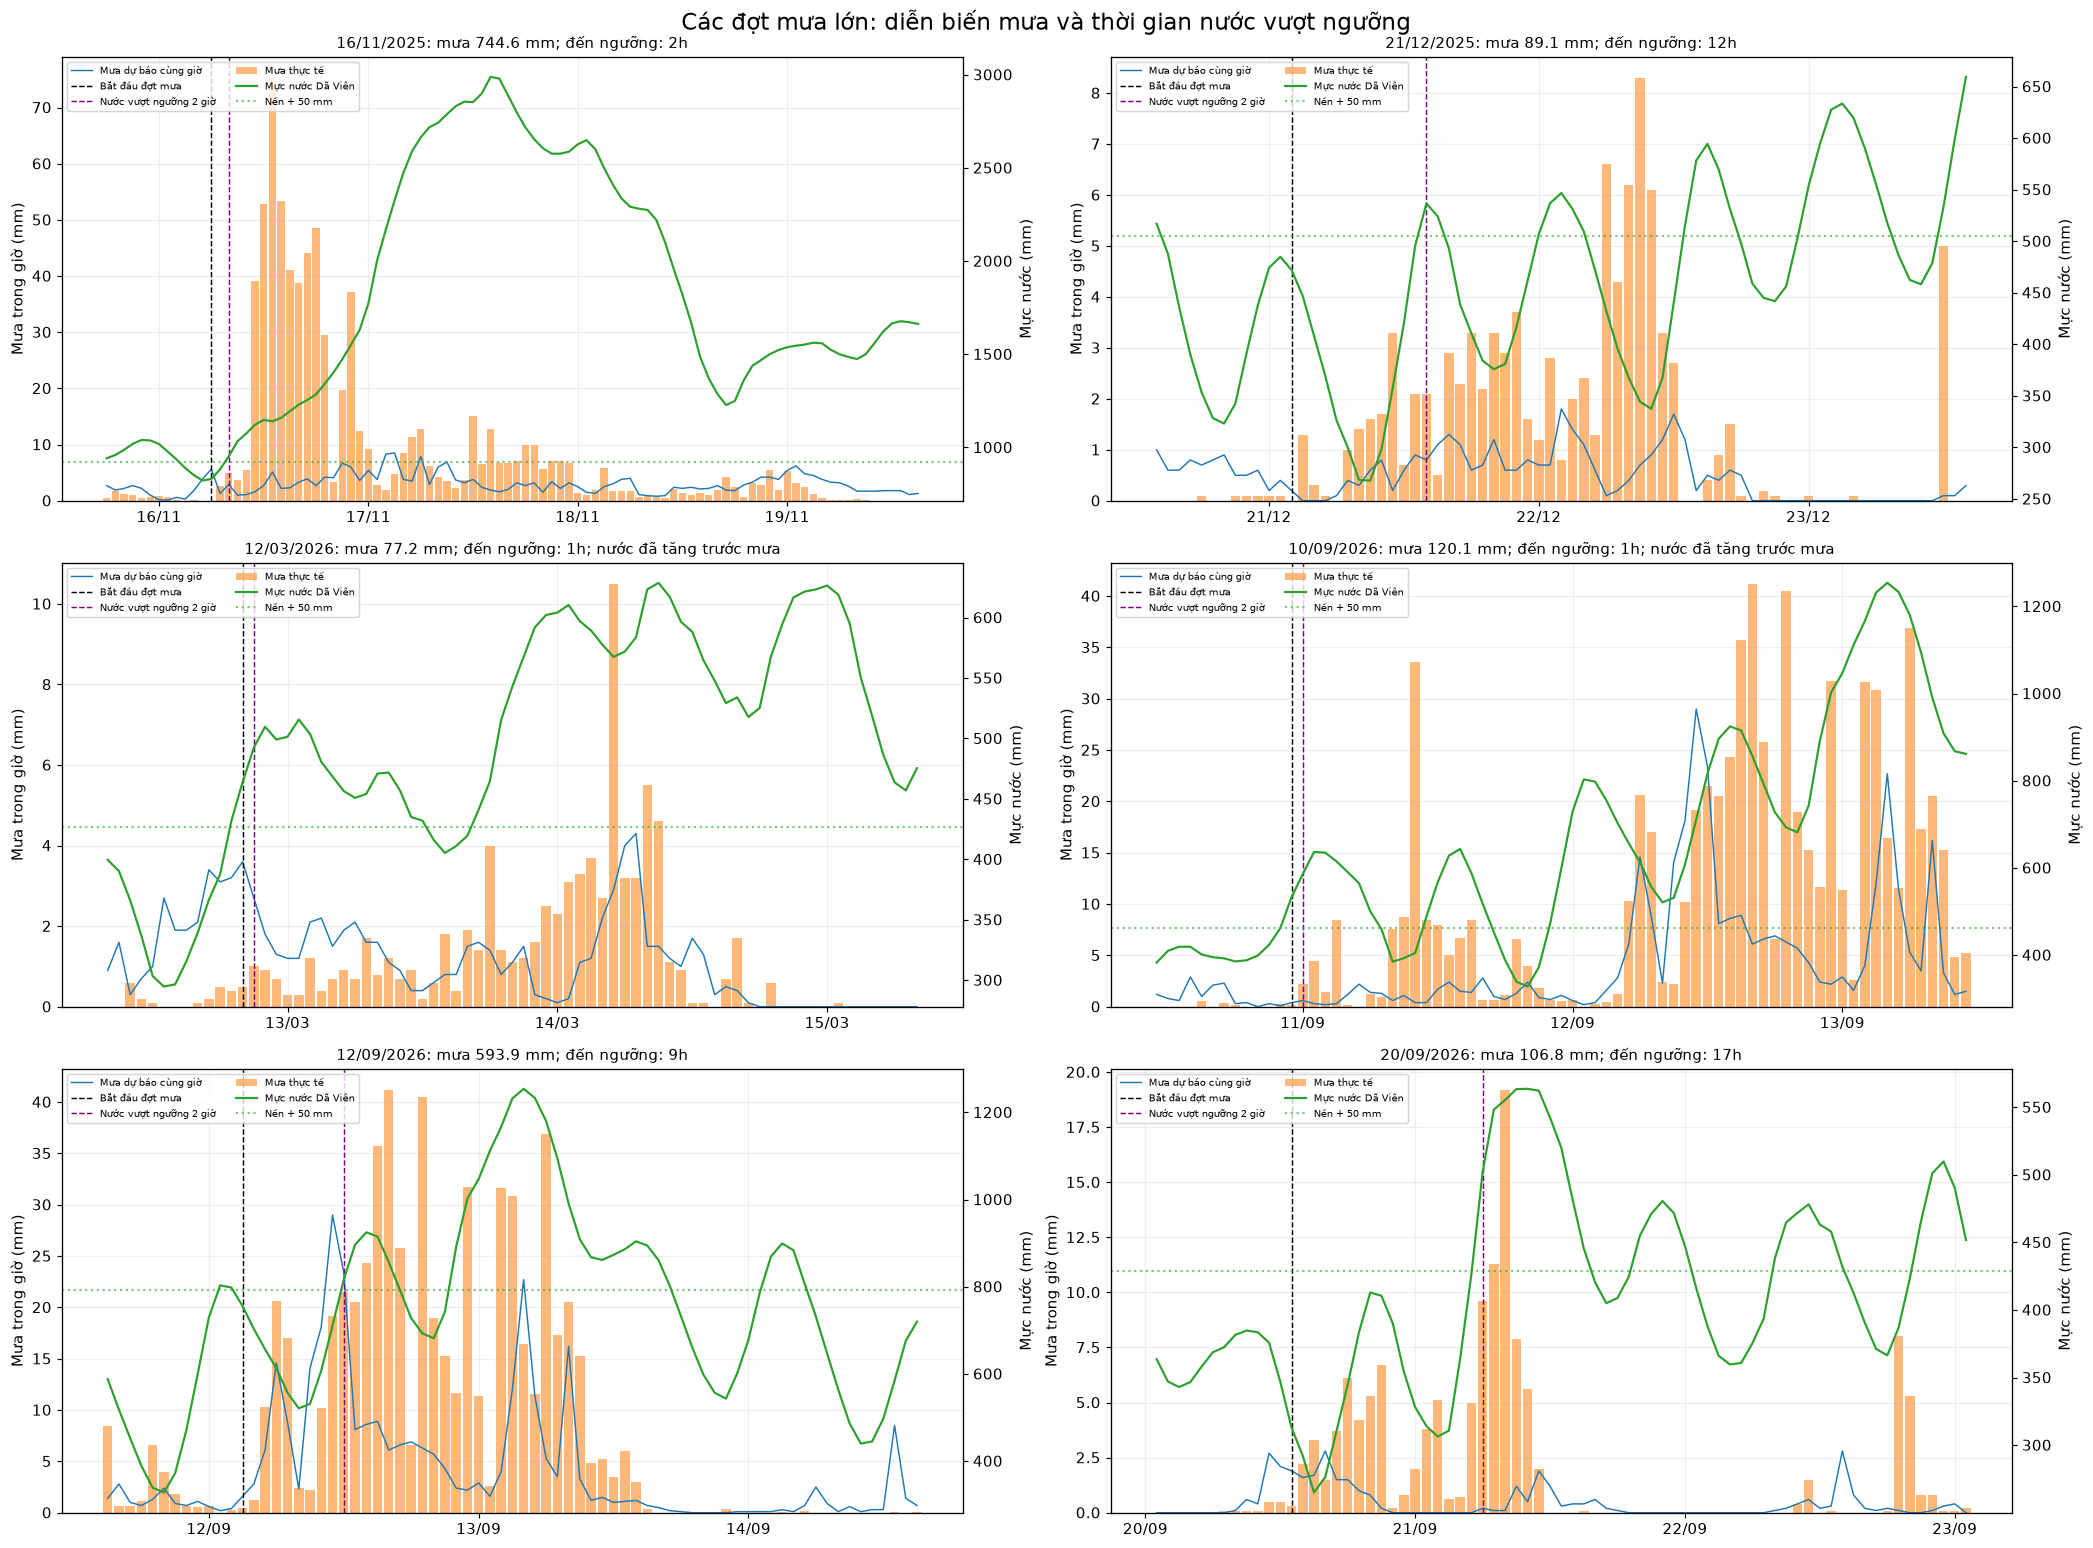

In [14]:
RAIN_WET_MM = 1.0
EVENT_MIN_TOTAL_MM = 50.0
RESPONSE_THRESHOLD_MM = 50.0
RESPONSE_WINDOW_H = 48
wet = analysis_hourly.index[analysis_hourly.observed_rain_mm >= RAIN_WET_MM]
groups = []
for stamp in wet:
    if not groups or stamp - groups[-1][-1] > pd.Timedelta(hours=6):
        groups.append([stamp])
    else:
        groups[-1].append(stamp)

event_records = []
for stamps in groups:
    first, last = stamps[0], stamps[-1]
    rain = analysis_hourly.observed_rain_mm.loc[first:last]
    if rain.isna().any() or rain.sum() < EVENT_MIN_TOTAL_MM:
        continue
    onset = first - pd.Timedelta(hours=1)
    prior_index = pd.date_range(onset - pd.Timedelta(hours=5), periods=6, freq='h')
    future_index = pd.date_range(onset + pd.Timedelta(hours=1), periods=49, freq='h')
    prior = analysis_hourly.water_level_mm.reindex(prior_index)
    future = analysis_hourly.water_level_mm.reindex(future_index)
    complete = prior.notna().all() and future.notna().all()
    baseline = prior.median() if prior.notna().all() else np.nan
    trend = prior.iloc[-1] - prior.iloc[-4] if prior.notna().all() else np.nan
    record = dict(event_id=len(event_records)+1, onset_utc=onset, end_utc=last,
                  total_rain_mm=rain.sum(), max_hour_rain_mm=rain.max(),
                  rain_peak_utc=rain.idxmax(), duration_hours=(last-onset).total_seconds()/3600,
                  baseline_water_mm=baseline, prior_3h_change_mm=trend,
                  already_rising=bool(trend >= 50) if pd.notna(trend) else None,
                  complete_water_window=bool(complete))
    for threshold in [25,50,100]:
        lag, response_time = np.nan, pd.NaT
        if complete:
            exceeds = future >= baseline + threshold
            consecutive = exceeds & exceeds.shift(-1, fill_value=False)
            hits = consecutive[consecutive].index
            if len(hits):
                response_time = hits[0]
                lag = (response_time-onset).total_seconds()/3600
        record[f'lag_{threshold}mm_hours'] = lag
        if threshold == 50:
            record['response_utc'] = response_time
    peak_index = pd.date_range(rain.idxmax(), periods=49, freq='h')
    after_peak = analysis_hourly.water_level_mm.reindex(peak_index)
    record['rain_peak_to_water_peak_hours'] = np.nan
    record['water_peak_utc'] = pd.NaT
    if after_peak.notna().all():
        wp = after_peak.idxmax()
        record['water_peak_utc'] = wp
        record['rain_peak_to_water_peak_hours'] = (wp-rain.idxmax()).total_seconds()/3600
    event_records.append(record)
event_lags = pd.DataFrame(event_records)
if event_lags.empty:
    raise ValueError('Không có đợt đạt ngưỡng đã chọn')
for col in ['onset_utc','end_utc','rain_peak_utc','response_utc','water_peak_utc']:
    event_lags[col] = pd.to_datetime(event_lags[col], utc=True)
for col in ['onset_utc','end_utc','response_utc']:
    event_lags[col.replace('_utc','_local')] = event_lags[col].dt.tz_convert(TZ)
summary_rows = []
for group_name, subset in [
    ('all_complete', event_lags[event_lags.complete_water_window]),
    ('not_already_rising', event_lags[event_lags.complete_water_window & (event_lags.already_rising == False)])]:
    for metric in ['lag_25mm_hours','lag_50mm_hours','lag_100mm_hours','rain_peak_to_water_peak_hours']:
        v = subset[metric].dropna()
        summary_rows.append(dict(group=group_name, metric=metric, eligible_events=len(subset),
            events_with_response=len(v), missing_response=len(subset)-len(v),
            min_hours=v.min(),max_hours=v.max(),mean_hours=v.mean(),median_hours=v.median()))
event_lag_summary = pd.DataFrame(summary_rows)
print(f'Tổng đợt đạt ngưỡng: {len(event_lags)}; đủ cửa sổ nước: {int(event_lags.complete_water_window.sum())}')
display(event_lag_summary.round(2))
display(event_lags[['event_id','onset_local','end_local','total_rain_mm','already_rising',
                    'complete_water_window','lag_50mm_hours','rain_peak_to_water_peak_hours']])
event_lags.to_csv(OUTPUT_DIR / 'rain_event_lags.csv',index=False)
event_lag_summary.to_csv(OUTPUT_DIR / 'rain_event_lag_summary.csv',index=False)

chosen_events = event_lags[event_lags.complete_water_window].nlargest(6,'total_rain_mm').sort_values('onset_utc')
fig, axes = plt.subplots(3,2,figsize=(20,15))
for ax, (_, ev) in zip(axes.flat, chosen_events.iterrows()):
    lo=ev.onset_utc-pd.Timedelta(hours=12)
    hi=max(ev.end_utc,ev.onset_utc+pd.Timedelta(hours=48))+pd.Timedelta(hours=12)
    view=analysis_hourly.loc[lo:hi].copy()
    view.index=view.index.tz_convert(TZ)
    ax.bar(view.index,view.observed_rain_mm,width=.035,alpha=.55,color='tab:orange',label='Mưa thực tế')
    ax.plot(view.index,view.forecast_rain_mm,color='tab:blue',linewidth=1,label='Mưa dự báo cùng giờ')
    ax.set_ylabel('Mưa trong giờ (mm)')
    wa=ax.twinx()
    wa.plot(view.index,view.water_level_mm,color='tab:green',linewidth=1.5,label='Mực nước Dã Viên')
    wa.axhline(ev.baseline_water_mm+50,color='tab:green',linestyle=':',alpha=.6,label='Nền + 50 mm')
    wa.set_ylabel('Mực nước (mm)')
    ax.axvline(ev.onset_utc.tz_convert(TZ),color='black',linestyle='--',linewidth=1,label='Bắt đầu đợt mưa')
    if pd.notna(ev.response_utc):
        ax.axvline(ev.response_utc.tz_convert(TZ),color='purple',linestyle='--',linewidth=1,label='Nước vượt ngưỡng 2 giờ')
    lag=f'{ev.lag_50mm_hours:.0f}h' if pd.notna(ev.lag_50mm_hours) else 'chưa thấy trong 48h'
    flag='; nước đã tăng trước mưa' if ev.already_rising else ''
    ax.set_title(f'{ev.onset_utc.tz_convert(TZ):%d/%m/%Y}: mưa {ev.total_rain_mm:.1f} mm; đến ngưỡng: {lag}{flag}',fontsize=10)
    ax.xaxis.set_major_locator(mdates.DayLocator(tz=view.index.tz))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m',tz=view.index.tz))
    ax.grid(alpha=.2)
    h1,l1=ax.get_legend_handles_labels();h2,l2=wa.get_legend_handles_labels()
    ax.legend(h1+h2,l1+l2,fontsize=7,loc='upper left',ncol=2)
for ax in axes.flat[len(chosen_events):]: ax.set_visible(False)
fig.suptitle('Các đợt mưa lớn: diễn biến mưa và thời gian nước vượt ngưỡng',fontsize=16)
finish(fig,'09_nhieu_dot_mua_lon_va_do_tre.png')

lines=['# Độ trễ mô tả theo nhiều đợt mưa lớn','',
    'Đợt: giờ mưa >=1 mm, tách khi cách >6 giờ; tổng đợt >=50 mm. '
    'Đáp ứng: hai giờ liên tiếp nước >= nền trung vị 6 giờ + ngưỡng; tìm trong 48 giờ. '
    'Đã tăng trước mưa: thay đổi 3 giờ trước đầu đợt >=50 mm.', '',
    f'Tổng đợt: {len(event_lags)}; đủ cửa sổ: {int(event_lags.complete_water_window.sum())}.', '',
    '| Nhóm | Chỉ số | Đủ cửa sổ | Có đáp ứng | Thiếu đáp ứng | Min h | Max h | Mean h | Median h |',
    '|---|---|---:|---:|---:|---:|---:|---:|---:|']
for r in event_lag_summary.itertuples():
    lines.append(f'| {r.group} | {r.metric} | {r.eligible_events} | {r.events_with_response} | '
        f'{r.missing_response} | {r.min_hours:.2f} | {r.max_hours:.2f} | {r.mean_hours:.2f} | {r.median_hours:.2f} |')
lines += ['', 'Đây là độ trễ vượt ngưỡng quan sát, không chứng minh thời gian truyền nước '
    'hay nguyên nhân do mưa. Dao động nước tự nhiên/điều tiết và mưa vùng khác có thể tạo đáp ứng. '
    'Độ trễ min theo lưới giờ là 1h. Đỉnh nước được tìm chỉ sau đỉnh mưa nên độ trễ đỉnh bị ràng buộc không âm. '
    'Thống kê bỏ các trường hợp không thấy đáp ứng; chúng được đếm riêng. Không áp dụng các số này làm feature mặc định.']
(OUTPUT_DIR/'rain_event_lag_report.md').write_text('\n'.join(lines)+'\n')


## 10. Bốn kiểm tra trước khi tạo dataset mới

Chạy module phân tích riêng trong cùng thư mục, không tạo dataset training:
1. Archive hai giai đoạn và quanh mốc chuyển phiên bản (mô tả, chưa chứng minh chất lượng vận hành).
2. Đánh giá đúng tổng mưa tương lai 0–3/3–6/6–12/12–24h của một bản tại mỗi anchor.
3. Độ phủ 96 bước, mask so với bỏ mẫu, ảnh hưởng lên các đợt nước cao.
4. Số đợt nước cao, tốc độ tăng và **mức nước thật sự xuất hiện làm target** sau warm-up.

Module dùng full per-run cache nếu có; nếu không thử kết nối DB chỉ đọc. Khi
không kết nối được, các phần tính từ snapshot/audit vẫn chạy, nhưng phần 2 được
ghi **chưa có kết quả**, không dựng giả bằng cách ghép dự báo của các bản khác nhau.
Kết quả chạy hiện tại phải đọc cùng `manifest.json` để biết mức độ hoàn thành.


| split | rows | baseline_sequences | complete_weather_at_anchor | complete_weather_all_96 | sequences_retained_with_masks | sequences_lost_if_drop_missing | fallback_complete_weather_all_96 | missing_timestep_pct |
|---|---|---|---|---|---|---|---|---|
| train | 6190 | 6095 | 6084 | 5894 | 6095 | 201 | 6095 | 0.178 |
| val | 1080 | 985 | 985 | 985 | 985 | 0 | 985 | 0.000 |
| test | 711 | 592 | 592 | 592 | 592 | 0 | 592 | 0.000 |
| split | rows | high_water_threshold_train_p95 | rising6_threshold_train_p95 | high_water_hours | rapid_rise_hours | event_peaks | uncensored_event_peaks | event_peaks_present_as_target | max_water_mm | max_water_at_eligible_anchor_mm | max_water_in_eligible_targets_mm | max_6h_rise_mm | rain_hour_p99 | heavy_rain_hours_ge10 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| train | 6190 | 691.120 | 155.711 | 310 | 310 | 7 | 6 | 6 | 2988.917 | 1677.433 | 1677.433 | 958.250 | 5.500 | 28 |
| val | 1080 | 691.120 | 155.711 | 44 | 36 | 1 | 1 | 1 | 

,scope,era,n,pearson_r,bias_mm,mae_mm,rmse_mm,observed_mean,forecast_mean,observed_wet_pct,forecast_wet_pct,forecast_p95,forecast_max
0,whole_period,49r1_hindcast_label,4288,0.3039,0.0119,0.4898,2.4616,0.3704,0.3823,6.8797,12.8731,2.000,17.0
1,whole_period,50r1_archive_label,3727,0.4768,-0.1108,0.5610,2.1507,0.4608,0.3500,7.3518,9.4178,1.700,29.0
2,transition_plus_minus_28d,after,672,0.2138,0.0540,0.2153,0.7178,0.0937,0.1478,2.2321,4.7619,0.900,4.3
3,transition_plus_minus_28d,before,672,0.0668,0.0244,0.3705,1.5720,0.1954,0.2198,2.9762,5.0595,0.945,13.7


,split,rows,baseline_sequences,complete_weather_at_anchor,complete_weather_all_96,sequences_retained_with_masks,sequences_lost_if_drop_missing,fallback_complete_weather_all_96,missing_timestep_pct
0,train,6190,6095,6084,5894,6095,201,6095,0.177706
1,val,1080,985,985,985,985,0,985,0.000000
2,test,711,592,592,592,592,0,592,0.000000


,split,group,n,water_max_mm,water_mean_mm,high_water_hours,rain_mean_mm,rain_max_mm
0,train,complete_weather96,5894,1677.43,485.24,215,0.19,33.8
1,train,would_drop_missing_weather,201,594.08,532.55,0,0.07,10.6
2,val,complete_weather96,985,1254.08,376.72,44,0.91,41.2
3,val,would_drop_missing_weather,0,NaN,NaN,0,NaN,NaN
4,test,complete_weather96,592,893.42,433.33,68,0.76,19.2
5,test,would_drop_missing_weather,0,NaN,NaN,0,NaN,NaN


,split,rows,high_water_threshold_train_p95,rising6_threshold_train_p95,high_water_hours,rapid_rise_hours,event_peaks,uncensored_event_peaks,event_peaks_present_as_target,max_water_mm,max_water_at_eligible_anchor_mm,max_water_in_eligible_targets_mm,max_6h_rise_mm,rain_hour_p99,heavy_rain_hours_ge10
0,train,6190,691.12,155.71,310,310,7,6,6,2988.92,1677.43,1677.43,958.25,5.50,28
1,val,1080,691.12,155.71,44,36,1,1,1,1254.08,1254.08,1254.08,489.08,20.79,27
2,test,711,691.12,155.71,68,133,1,1,1,893.42,893.42,893.42,441.35,10.18,9


,scope,window,heavy_threshold_mm,eligible_anchors,actual_complete,paired_coverage_pct,n,pearson_r,bias_mm,mae_mm,rmse_mm
0,all,0-3h,8.00,8026,8023,99.8256,8012,0.4638,-0.1297,1.4655,6.0453
1,train,0-3h,8.00,6187,6184,99.7737,6173,0.3643,0.1143,1.2091,5.6758
2,val,0-3h,8.00,1077,1077,100.0000,1077,0.6658,-0.9798,2.2618,8.1134
3,test,0-3h,8.00,708,708,100.0000,708,0.1165,-1.0685,2.4886,5.6470
4,all,3-6h,8.00,8023,8020,99.8255,8009,0.4776,-0.1365,1.4779,5.9997
5,train,3-6h,8.00,6184,6181,99.7736,6170,0.4083,0.1274,1.2170,5.5615
6,val,3-6h,8.00,1074,1074,100.0000,1074,0.6576,-1.1082,2.3108,8.3048
7,test,3-6h,8.00,705,705,100.0000,705,0.0990,-1.0533,2.5237,5.7105
8,all,6-12h,13.50,8017,8011,99.7880,8000,0.5122,-0.2108,2.7866,10.9729
9,train,6-12h,13.50,6178,6172,99.7248,6161,0.4297,0.2479,2.2869,10.2583


,scope,window,threshold_train_wet_p90,true_heavy,actual_heavy_all,actual_heavy_missing_forecast,hits,misses,false_alarms,recall,precision
0,all,0-3h,8.00,289,289,0,90,199,151,0.3114,0.3734
1,train,0-3h,8.00,153,153,0,61,92,112,0.3987,0.3526
2,val,0-3h,8.00,72,72,0,28,44,24,0.3889,0.5385
3,test,0-3h,8.00,64,64,0,1,63,11,0.0156,0.0833
4,all,3-6h,8.00,289,289,0,91,198,163,0.3149,0.3583
5,train,3-6h,8.00,153,153,0,65,88,120,0.4248,0.3514
6,val,3-6h,8.00,72,72,0,26,46,24,0.3611,0.5200
7,test,3-6h,8.00,64,64,0,0,64,15,0.0000,0.0000
8,all,6-12h,13.50,358,358,0,112,246,169,0.3128,0.3986
9,train,6-12h,13.50,198,198,0,82,116,127,0.4141,0.3923


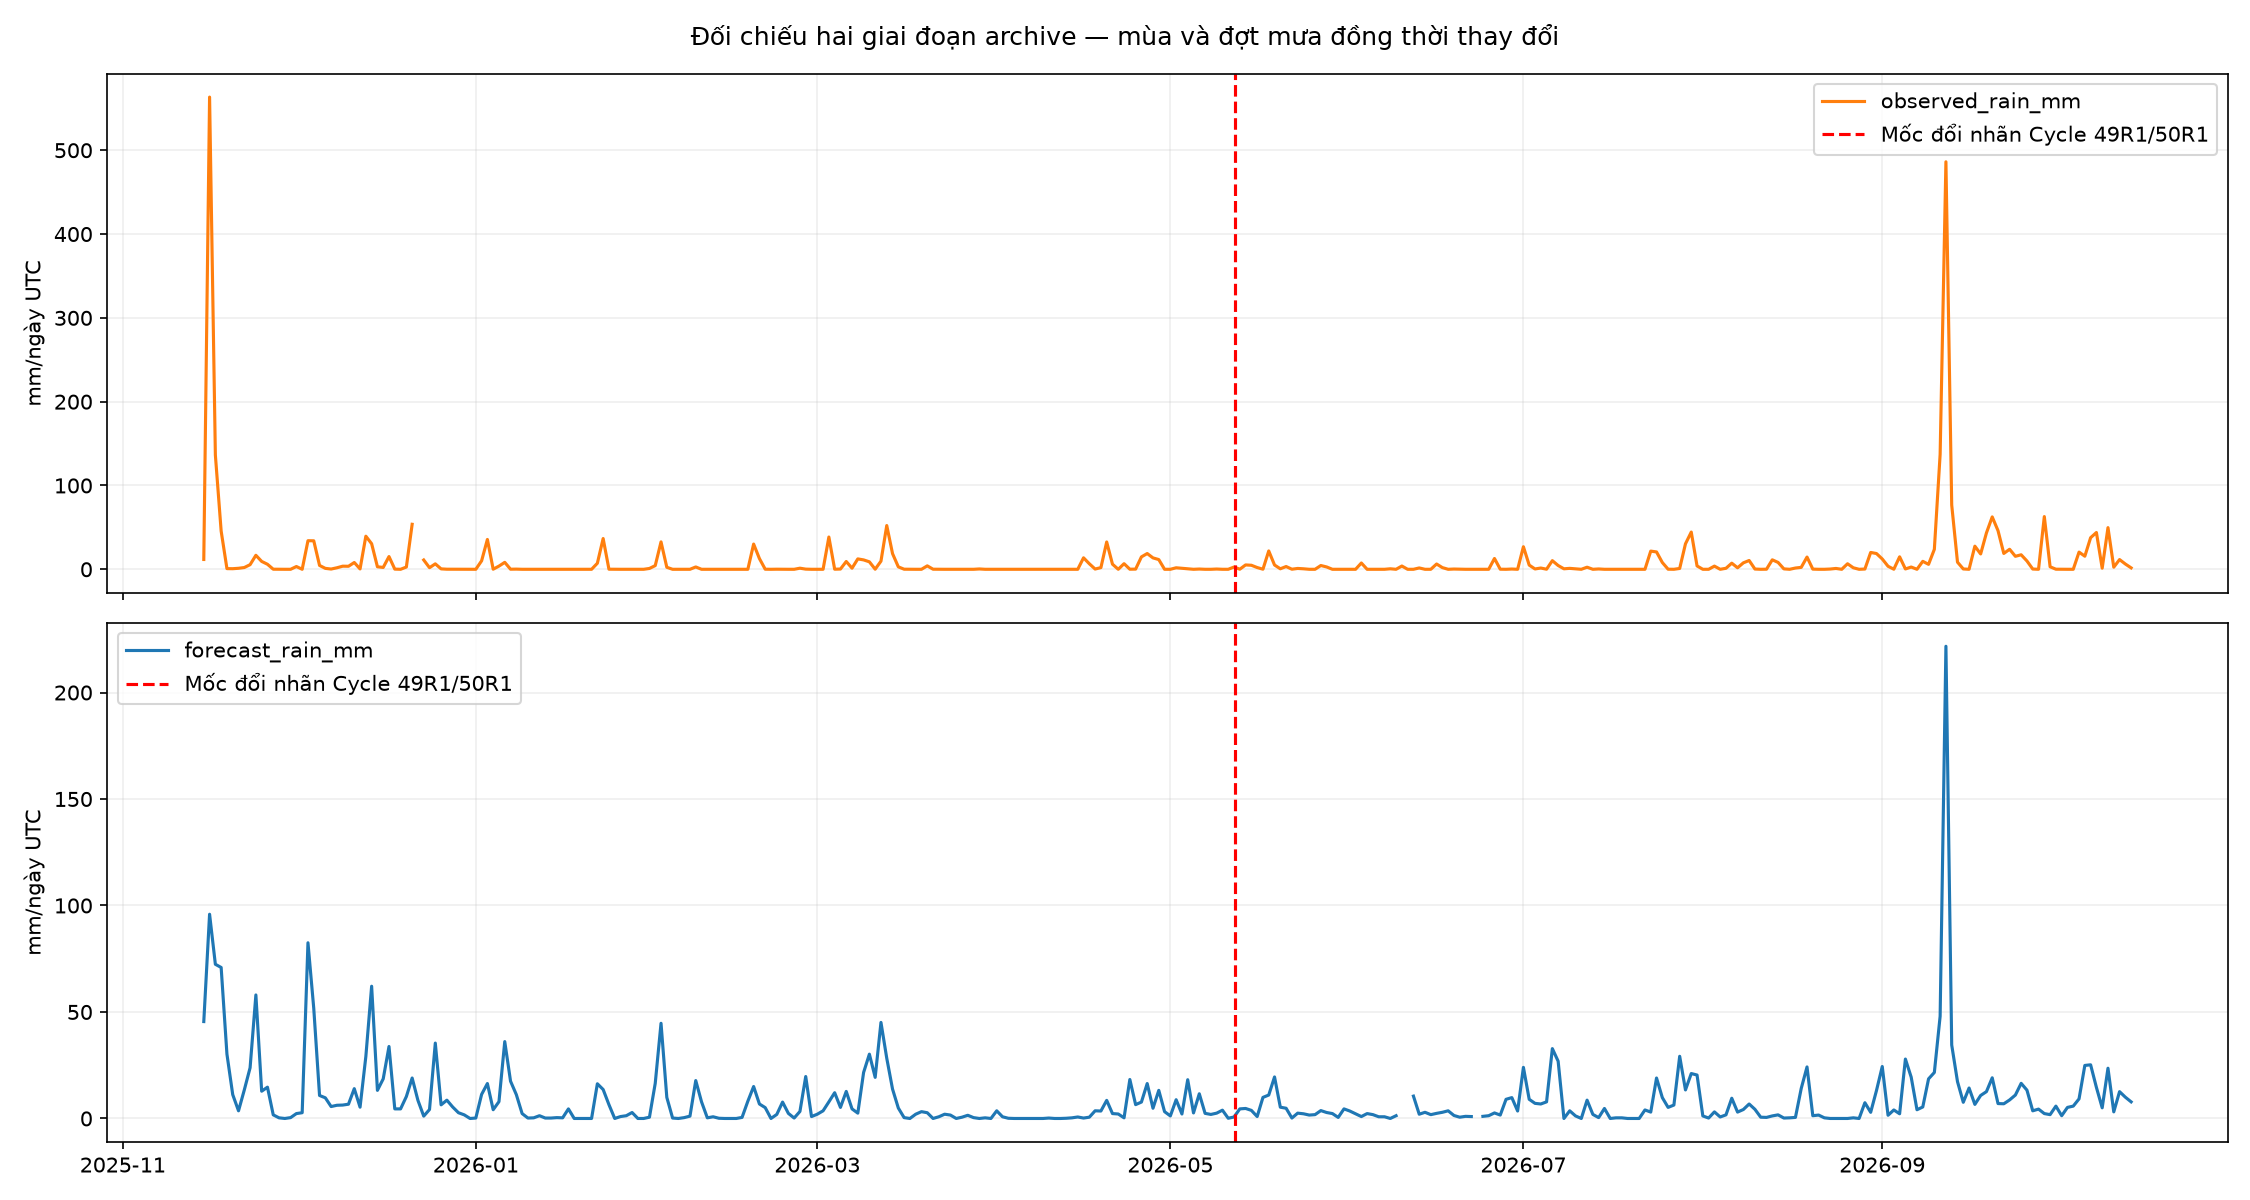

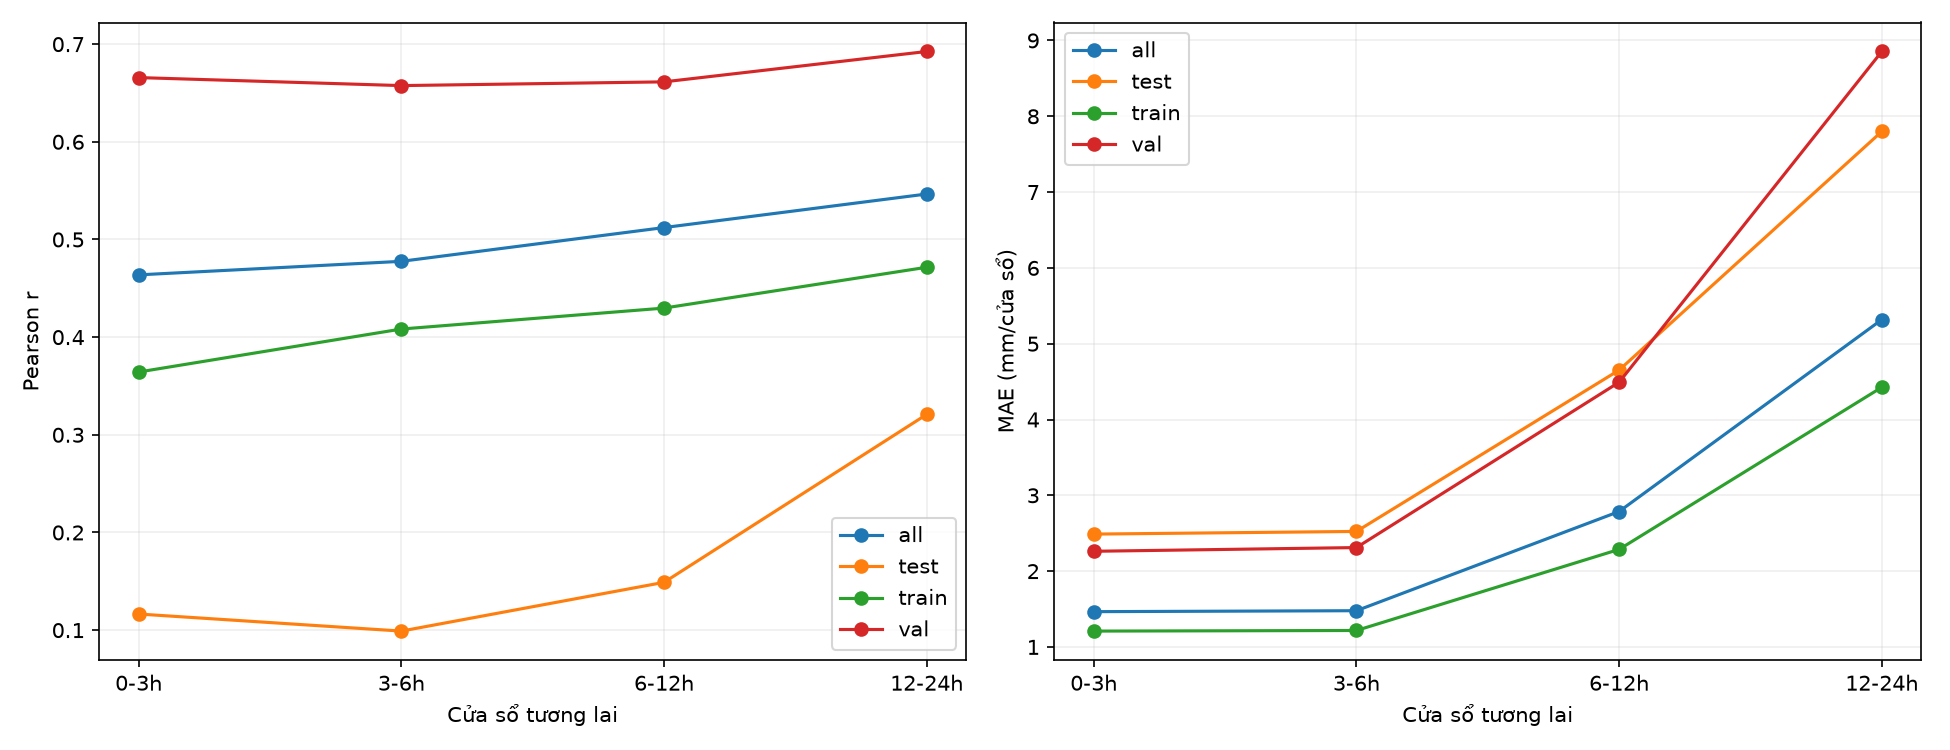

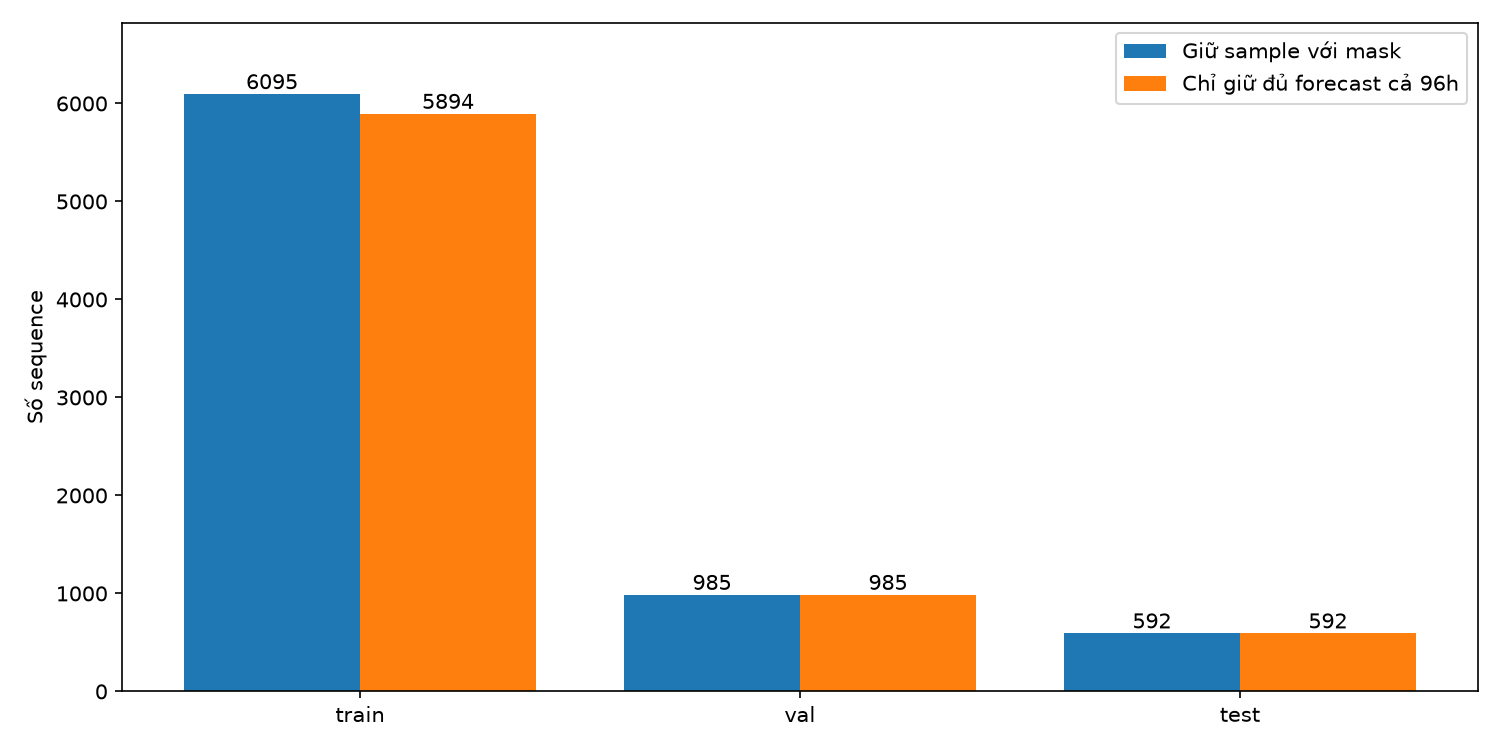

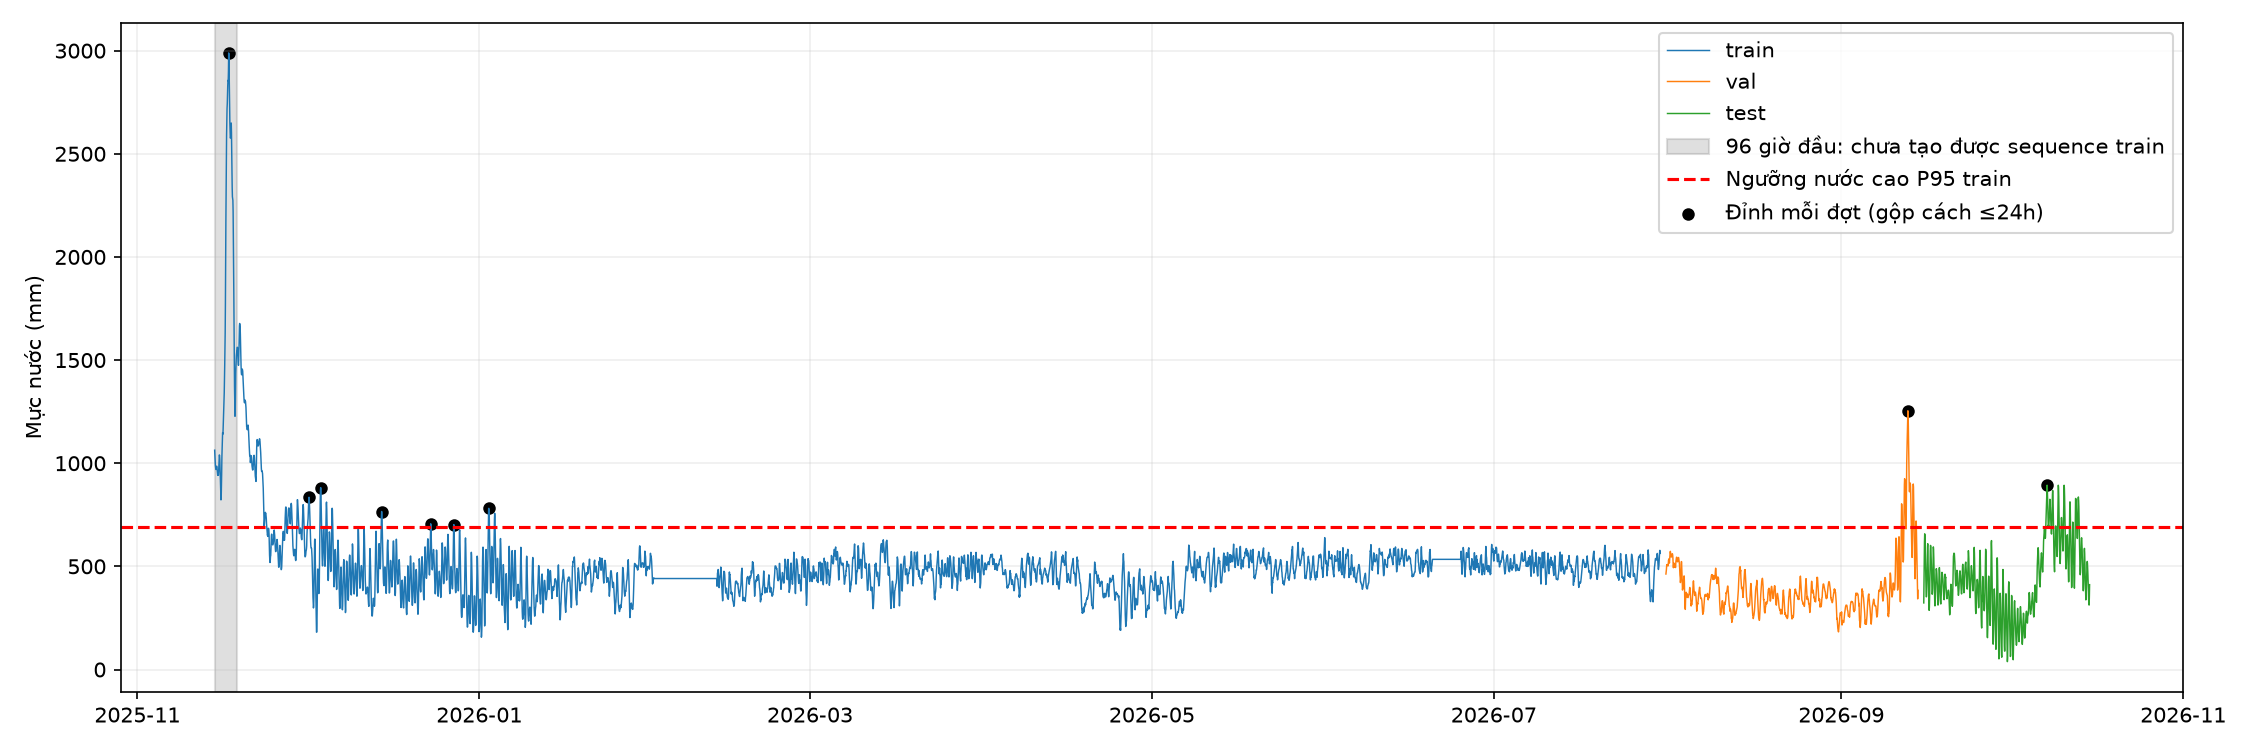

# Bốn kiểm tra trước khi tạo dataset dự báo mưa

Chưa tạo dataset training, không thay split hoặc cấu hình model. Toàn bộ bảng là sản phẩm phân tích.

## Các phát hiện chính

- Bỏ sequence thiếu forecast sẽ mất 201 trên 6095 sequence train; mask giữ nguyên số mẫu.
- Đỉnh nước thô train 2988.9 mm; cao nhất làm target sau warm-up chỉ 1677.4 mm. Đỉnh đầu snapshot vẫn có thể nằm trong lịch sử đầu vào, nhưng không có mẫu dự báo đỉnh đó làm nhãn.
- Các sequence bị loại vì forecast thiếu trong snapshot này không trùng giờ nước cao theo ngưỡng P95 train; không khẳng định điều này đúng cho dữ liệu mới.
- Train/val/test chỉ có lần lượt 7/1/1 đỉnh đợt nước cao theo quy tắc gộp 24h; một đợt train bị cắt ở đầu snapshot. Không coi số giờ là số đợt độc lập.
- Đã đánh giá đủ bốn cửa sổ tương lai trên full per-run cache.

## Trạng thái nguồn

Nguồn per-run: **cached_full_vintages**; lỗi kết nối (không chứa secret): `None`.
Quan trắc trong bảng xuất đã được đối chiếu với snapshot dataset (sai khác tối đa ≤1e-6).

## 1. Hai giai đoạn archive

| scope | era | n | pearson_r | bias_mm | mae_mm | rmse_mm | observed_mean | forecast_mean | observed_wet_pct | forecast_wet_pct | forecast_p95 | forecast_max |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| whole_period | 49r1_hindcast_label | 4288 | 0.304 | 0.012 | 0.490 | 2.462 | 0.370 | 0.382 | 6.880 | 12.873 | 2.000 | 17.000 |
| whole_period | 50r1_archive_label | 3727 | 0.477 | -0.111 | 0.561 | 2.151 | 0.461 | 0.350 | 7.352 | 9.418 | 1.700 | 29.000 |
| transition_plus_minus_28d | after | 672 | 0.214 | 0.054 | 0.215 | 0.718 | 0.094 | 0.148 | 2.232 | 4.762 | 0.900 | 4.300 |
| transition_plus_minus_28d | before | 672 | 0.067 | 0.024 | 0.371 | 1.572 | 0.195 | 0.220 | 2.976 | 5.060 | 0.945 | 13.700 |

Nhãn 49R1/hindcast và 50R1 lấy từ quy ước collector theo tài liệu nhà cung cấp; không phải xác minh độc lập bản gốc đã được phát hành lịch sử. Giờ khởi tạo không phải giờ công bố. available_at chưa xác minh, giả định trễ 6 giờ. Chênh lệch hai giai đoạn đồng thời bị nhiễu bởi mùa/đợt mưa; cửa sổ ±28 ngày chỉ mô tả, không tách được tác động đổi model.

## 2. Đánh giá đúng bốn cửa sổ tương lai

| scope | window | heavy_threshold_mm | eligible_anchors | actual_complete | paired_coverage_pct | n | pearson_r | bias_mm | mae_mm | rmse_mm |
|---|---|---|---|---|---|---|---|---|---|---|
| all | 0-3h | 8.000 | 8026 | 8023 | 99.826 | 8012 | 0.464 | -0.130 | 1.465 | 6.045 |
| train | 0-3h | 8.000 | 6187 | 6184 | 99.774 | 6173 | 0.364 | 0.114 | 1.209 | 5.676 |
| val | 0-3h | 8.000 | 1077 | 1077 | 100.000 | 1077 | 0.666 | -0.980 | 2.262 | 8.113 |
| test | 0-3h | 8.000 | 708 | 708 | 100.000 | 708 | 0.117 | -1.069 | 2.489 | 5.647 |
| all | 3-6h | 8.000 | 8023 | 8020 | 99.826 | 8009 | 0.478 | -0.137 | 1.478 | 6.000 |
| train | 3-6h | 8.000 | 6184 | 6181 | 99.774 | 6170 | 0.408 | 0.127 | 1.217 | 5.561 |
| val | 3-6h | 8.000 | 1074 | 1074 | 100.000 | 1074 | 0.658 | -1.108 | 2.311 | 8.305 |
| test | 3-6h | 8.000 | 705 | 705 | 100.000 | 705 | 0.099 | -1.053 | 2.524 | 5.711 |
| all | 6-12h | 13.500 | 8017 | 8011 | 99.788 | 8000 | 0.512 | -0.211 | 2.787 | 10.973 |
| train | 6-12h | 13.500 | 6178 | 6172 | 99.725 | 6161 | 0.430 | 0.248 | 2.287 | 10.258 |
| val | 6-12h | 13.500 | 1068 | 1068 | 100.000 | 1068 | 0.661 | -1.754 | 4.492 | 15.352 |
| test | 6-12h | 13.500 | 699 | 699 | 100.000 | 699 | 0.149 | -2.035 | 4.652 | 9.397 |
| all | 12-24h | 20.950 | 8005 | 7993 | 99.713 | 7982 | 0.547 | -0.237 | 5.318 | 19.655 |
| train | 12-24h | 20.950 | 6166 | 6154 | 99.627 | 6143 | 0.472 | 0.860 | 4.426 | 17.932 |
| val | 12-24h | 20.950 | 1056 | 1056 | 100.000 | 1056 | 0.692 | -4.433 | 8.855 | 30.267 |
| test | 12-24h | 20.950 | 687 | 687 | 100.000 | 687 | 0.321 | -3.813 | 7.800 | 13.935 |

Ngưỡng mưa lớn cố định từ train; xem 02_heavy_rain_detection.csv. Bản dự báo được chọn tại từng anchor, không thay run giữa các giờ trong một cửa sổ.

### Khả năng nhận biết mưa lớn

| scope | window | threshold_train_wet_p90 | true_heavy | actual_heavy_all | actual_heavy_missing_forecast | hits | misses | false_alarms | recall | precision |
|---|---|---|---|---|---|---|---|---|---|---|
| all | 0-3h | 8.000 | 289 | 289 | 0 | 90 | 199 | 151 | 0.311 | 0.373 |
| train | 0-3h | 8.000 | 153 | 153 | 0 | 61 | 92 | 112 | 0.399 | 0.353 |
| val | 0-3h | 8.000 | 72 | 72 | 0 | 28 | 44 | 24 | 0.389 | 0.538 |
| test | 0-3h | 8.000 | 64 | 64 | 0 | 1 | 63 | 11 | 0.016 | 0.083 |
| all | 3-6h | 8.000 | 289 | 289 | 0 | 91 | 198 | 163 | 0.315 | 0.358 |
| train | 3-6h | 8.000 | 153 | 153 | 0 | 65 | 88 | 120 | 0.425 | 0.351 |
| val | 3-6h | 8.000 | 72 | 72 | 0 | 26 | 46 | 24 | 0.361 | 0.520 |
| test | 3-6h | 8.000 | 64 | 64 | 0 | 0 | 64 | 15 | 0.000 | 0.000 |
| all | 6-12h | 13.500 | 358 | 358 | 0 | 112 | 246 | 169 | 0.313 | 0.399 |
| train | 6-12h | 13.500 | 198 | 198 | 0 | 82 | 116 | 127 | 0.414 | 0.392 |
| val | 6-12h | 13.500 | 77 | 77 | 0 | 29 | 48 | 29 | 0.377 | 0.500 |
| test | 6-12h | 13.500 | 83 | 83 | 0 | 1 | 82 | 9 | 0.012 | 0.100 |
| all | 12-24h | 20.950 | 442 | 442 | 0 | 170 | 272 | 184 | 0.385 | 0.480 |
| train | 12-24h | 20.950 | 261 | 261 | 0 | 128 | 133 | 149 | 0.490 | 0.462 |
| val | 12-24h | 20.950 | 71 | 71 | 0 | 34 | 37 | 32 | 0.479 | 0.515 |
| test | 12-24h | 20.950 | 104 | 104 | 0 | 8 | 96 | 3 | 0.077 | 0.727 |

Ngưỡng P90 trong các tổng mưa dương của train, không phải định nghĩa khí tượng. Recall/precision tính trên các cửa sổ hợp lệ và chồng lấn, không phải số đợt mưa độc lập. Các trường hợp mưa lớn thiếu forecast được đếm riêng. Không chỉnh ngưỡng theo test. Correlation và recall ở test thấp hơn validation; không đảm bảo thêm forecast sẽ cải thiện mô hình nước.

## 3. Độ phủ sequence 96 giờ

| split | rows | baseline_sequences | complete_weather_at_anchor | complete_weather_all_96 | sequences_retained_with_masks | sequences_lost_if_drop_missing | fallback_complete_weather_all_96 | missing_timestep_pct |
|---|---|---|---|---|---|---|---|---|
| train | 6190 | 6095 | 6084 | 5894 | 6095 | 201 | 6095 | 0.178 |
| val | 1080 | 985 | 985 | 985 | 985 | 0 | 985 | 0.000 |
| test | 711 | 592 | 592 | 592 | 592 | 0 | 592 | 0.000 |

Baseline phản ánh loader: đủ 96 hàng trong cùng split, đủ năm target và nước hiện tại. Mask giữ nguyên số sequence nhưng không đảm bảo forecast có thông tin. Nếu chỉ dùng audit cache, cờ đủ 24 giờ lấy từ audit đã lưu cùng checksum split; chỉ kết luận độ phủ CHUNG bốn cửa sổ, chưa kết luận từng cửa sổ riêng. Fallback bản cũ được kiểm tra từ full per-run khi có cache; không suy diễn từ cache ghép. Bản cũ phải đủ 24 giờ tương lai, khởi tạo ít nhất 6 giờ trước anchor và không cũ quá 24 giờ. Cần mang theo độ cũ và cờ fallback; đây vẫn là giả định khả dụng lịch sử.

## 4. Độ đại diện theo split

| split | rows | high_water_threshold_train_p95 | rising6_threshold_train_p95 | high_water_hours | rapid_rise_hours | event_peaks | uncensored_event_peaks | event_peaks_present_as_target | max_water_mm | max_water_at_eligible_anchor_mm | max_water_in_eligible_targets_mm | max_6h_rise_mm | rain_hour_p99 | heavy_rain_hours_ge10 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| train | 6190 | 691.120 | 155.711 | 310 | 310 | 7 | 6 | 6 | 2988.917 | 1677.433 | 1677.433 | 958.250 | 5.500 | 28 |
| val | 1080 | 691.120 | 155.711 | 44 | 36 | 1 | 1 | 1 | 1254.083 | 1254.083 | 1254.083 | 489.083 | 20.789 | 27 |
| test | 711 | 691.120 | 155.711 | 68 | 133 | 1 | 1 | 1 | 893.417 | 893.417 | 893.417 | 441.350 | 10.180 | 9 |

Đợt nước cao: nước ≥P95 train, gộp các giờ vượt ngưỡng cách nhau ≤24h; đếm theo split của đỉnh. Đây là quy tắc mô tả, không phải định nghĩa lũ chính thức hoặc chứng minh các đợt độc lập. CSV sự kiện có cờ vượt qua split/cận snapshot, độ tăng 6 giờ và độ phủ sequence. Ngưỡng tăng nhanh cũng dùng P95 train; không điều chỉnh theo test.

## Kết luận hành động

- Kiểm tra cột max_water_in_eligible_targets_mm: sequence warm-up có thể loại đỉnh nước lớn ở đầu snapshot dù đỉnh vẫn xuất hiện trong train.csv thô.
- Giữ split hiện tại cho đối chiếu bước 1; test đã được xem nhiều lần nên không còn là holdout chưa chạm.
- Không loại toàn bộ sequence có forecast thiếu trước khi đánh giá ảnh hưởng lên các đợt nước cao; ưu tiên mask rõ ràng.
- Không gọi dữ liệu hindcast là replay vận hành đã xác minh. Chưa chốt có thể gộp hai phiên bản để train từ các bảng mô tả.
- Chưa tuyên bố bốn cửa sổ cải thiện model nước: cần thí nghiệm model có kiểm soát sau đánh giá dữ liệu.
- Dành dữ liệu mới sau cutoff làm kiểm chứng cuối; không kéo dữ liệu quan trắc tương lai vào dataset này.


In [15]:
from research.weather_forecast.analyze_dataset_readiness import main as run_readiness
from IPython.display import Image, Markdown
readiness_dir = run_readiness([])
readiness_manifest = json.loads((readiness_dir / 'manifest.json').read_text())
print('Phần 2 đã có số liệu đầy đủ:', readiness_manifest['part_2_complete'])
print('Nguồn per-run:', readiness_manifest['per_run_source'])
display(pd.read_csv(readiness_dir / '01_archive_regimes.csv').round(4))
display(pd.read_csv(readiness_dir / '03_sequence_coverage.csv'))
display(pd.read_csv(readiness_dir / '03_missing_sequence_context.csv').round(2))
display(pd.read_csv(readiness_dir / '04_split_representativeness.csv').round(2))
if readiness_manifest['part_2_complete']:
    display(pd.read_csv(readiness_dir / '02_future_window_metrics.csv').round(4))
    display(pd.read_csv(readiness_dir / '02_heavy_rain_detection.csv').round(4))
else:
    print('CHƯA tính độ đúng các cửa sổ dự báo: cần toàn bộ giờ tương lai của cùng một run.')
    display(pd.read_csv(readiness_dir / '02_observed_window_distributions.csv').round(3))
for filename in ['01_archive_regimes.png','02_future_windows.png','03_sequence_coverage.png','04_high_water_events.png']:
    if (readiness_dir / filename).exists():
        display(Image(filename=str(readiness_dir / filename)))
display(Markdown((readiness_dir / 'bao_cao.md').read_text()))
